<a href="https://colab.research.google.com/github/DeepikaTyagi26/Almabetter-Projects-/blob/main/Zomato_Restaurant_Clustering_ML_Submission_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project Name**    -  Zomato Restaurant Clustering



##### **Project Type**    - Unsupervised
##### **Contribution**    - Individual
##### **Developed by -**   DEEPIKA TYAGI


# **Project Summary -**

Zomato, one of India’s leading restaurant aggregators and food delivery services, plays a vital role in shaping how customers discover, rate, and interact with restaurants. Given India’s cultural and culinary diversity, the restaurant industry is vast and dynamic. This project explores data from Zomato to uncover insights about restaurants across Indian cities, with a dual focus on improving customer experience and driving data-informed business decisions for the company.

# **GitHub Link -**

Provide your GitHub Link here.

# **Problem Statement**


The core problem is twofold:

For Customers: How can we help users find the best restaurants in their locality that align with their taste preferences, budget, and expectations based on real customer experiences and sentiment?

For Zomato (the Company): How can the company better understand restaurant performance across cities by analyzing customer feedback, identifying service gaps, and segmenting restaurants into strategic business clusters for improved decision-making?

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:


# Data manipulation
import pandas as pd
import numpy as np
import gdown

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns


# Text Processing and NLP (for sentiment analysis)
from textblob import TextBlob
import re  # Regular expressions for text cleaning

# Machine Learning
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Warnings
import warnings
warnings.filterwarnings('ignore')


### Dataset Loading

In [2]:
# Define file IDs
file_id1 = '1m4lylf_iAyxlsIW1uTGrMSuhHYwuntJl'
file_id2 = '1JG_8OGZ6tS-0SOstH_x3n9sN0ZI1AFNC'

# Define output file names
output1 = 'zomato_metadata.csv'
output2 = 'zomato_reviews.csv'

# Download the files
gdown.download(f'https://drive.google.com/uc?id={file_id1}', output1, quiet=False)
gdown.download(f'https://drive.google.com/uc?id={file_id2}', output2, quiet=False)

Downloading...
From: https://drive.google.com/uc?id=1m4lylf_iAyxlsIW1uTGrMSuhHYwuntJl
To: /content/zomato_metadata.csv
100%|██████████| 18.0k/18.0k [00:00<00:00, 25.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1JG_8OGZ6tS-0SOstH_x3n9sN0ZI1AFNC
To: /content/zomato_reviews.csv
100%|██████████| 3.58M/3.58M [00:00<00:00, 142MB/s]


'zomato_reviews.csv'

### Dataset First View

In [3]:
# Load the downloaded CSV files
df_metadata = pd.read_csv('zomato_metadata.csv')
df_reviews = pd.read_csv('zomato_reviews.csv')

# Now preview the datasets
print("Zomato Metadata Dataset (df_metadata):")
display(df_metadata.head())

print("\nZomato Reviews Dataset (df_reviews):")
display(df_reviews.head())



Zomato Metadata Dataset (df_metadata):


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."



Zomato Reviews Dataset (df_reviews):


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


### Dataset Rows & Columns count

In [4]:
# Check shape of Metadata Dataset
rows_meta, cols_meta = df_metadata.shape
print(f"📊 Metadata Dataset: {rows_meta} rows and {cols_meta} columns")

# Check shape of Reviews Dataset
rows_reviews, cols_reviews = df_reviews.shape
print(f"📝 Reviews Dataset: {rows_reviews} rows and {cols_reviews} columns")


📊 Metadata Dataset: 105 rows and 6 columns
📝 Reviews Dataset: 10000 rows and 7 columns


### Dataset Information

In [5]:
# Dataset Info for Metadata
print("🗂️ Zomato Metadata Dataset Info:")
df_metadata.info()

print("\n🗂️ Zomato Reviews Dataset Info:")
df_reviews.info()


🗂️ Zomato Metadata Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    object
 3   Collections  51 non-null     object
 4   Cuisines     105 non-null    object
 5   Timings      104 non-null    object
dtypes: object(6)
memory usage: 5.1+ KB

🗂️ Zomato Reviews Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time        9962 non-null   object
 6   Pictures    10000 non-null  in

#### Duplicate Values

In [6]:
# Check duplicates in Metadata dataset
duplicate_metadata = df_metadata.duplicated().sum()
print(f"🔁 Duplicate rows in Metadata Dataset: {duplicate_metadata}")

# Check duplicates in Reviews dataset
duplicate_reviews = df_reviews.duplicated().sum()
print(f"🔁 Duplicate rows in Reviews Dataset: {duplicate_reviews}")


🔁 Duplicate rows in Metadata Dataset: 0
🔁 Duplicate rows in Reviews Dataset: 36


#### Missing Values/Null Values

In [7]:
# Missing values in Metadata dataset
print("📉 Missing Values in Metadata Dataset:")
missing_meta = df_metadata.isnull().sum()
print(missing_meta[missing_meta > 0])  # Show only columns with missing values

# Missing values in Reviews dataset
print("\n📉 Missing Values in Reviews Dataset:")
missing_reviews = df_reviews.isnull().sum()
print(missing_reviews[missing_reviews > 0])  # Show only columns with missing values


📉 Missing Values in Metadata Dataset:
Collections    54
Timings         1
dtype: int64

📉 Missing Values in Reviews Dataset:
Reviewer    38
Review      45
Rating      38
Metadata    38
Time        38
dtype: int64


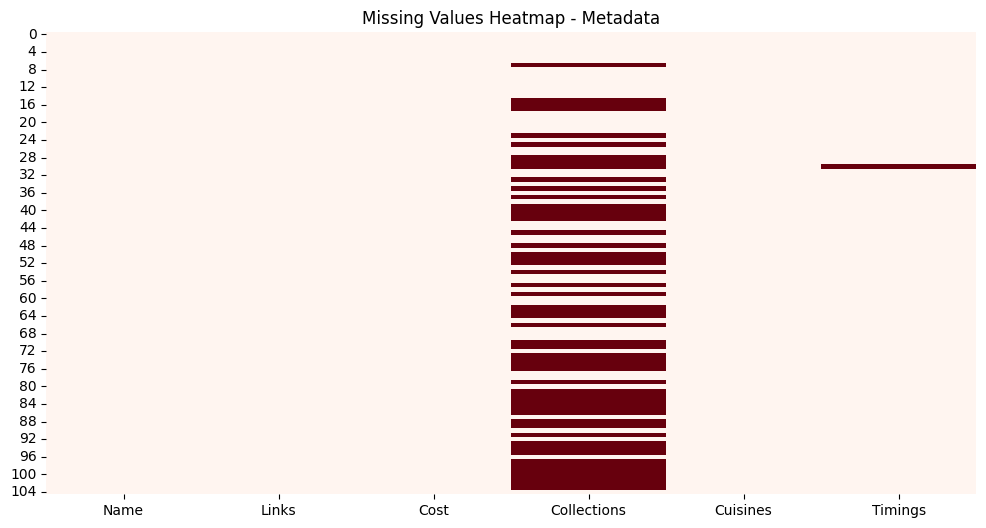

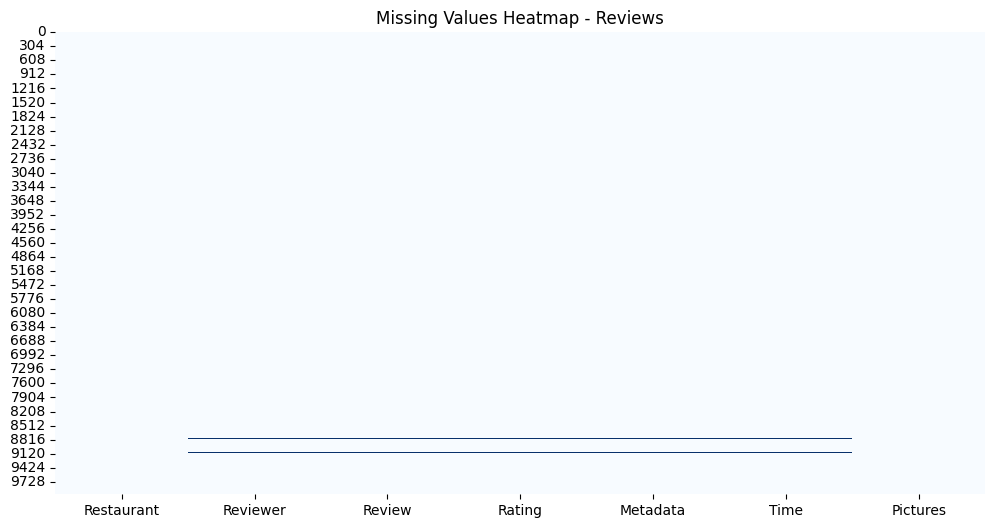

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# Heatmap for Metadata
plt.figure(figsize=(12,6))
sns.heatmap(df_metadata.isnull(), cbar=False, cmap='Reds')
plt.title("Missing Values Heatmap - Metadata")
plt.show()

# Heatmap for Reviews
plt.figure(figsize=(12,6))
sns.heatmap(df_reviews.isnull(), cbar=False, cmap='Blues')
plt.title("Missing Values Heatmap - Reviews")
plt.show()


### What did you know about your dataset?

After performing initial loading, inspection, and exploration of the Zomato datasets, here are the key insights:

🗂️ Zomato Metadata Dataset
This dataset contains restaurant-level information such as:

Restaurant names

Location (city/locality)

Cuisines offered

Cost

Rating

There are missing values in important fields like rate, location, and rest_type, which need to be handled.

Ratings are often in text form (e.g., "4.1/5") and need to be converted to numerical values for analysis.

The dataset has a large number of unique cuisines and restaurant types, which are valuable for segmentation and clustering.

💬 Zomato Reviews Dataset
This dataset includes:

Customer reviews

Restaurant linkage (e.g., name )

Review content (which can be used for sentiment analysis)

Some reviews are missing or are written in a mix of languages, which may require NLP pre-processing like tokenization, stopword removal, and language filtering.

This dataset will be used to understand customer sentiment trends, such as what people like or complain about in restaurants.

⚙️ Combined Potential
These datasets can be merged using a common identifier (like restaurant name) to allow:

Sentiment analysis combined with ratings

Cluster formation of restaurants based on features like price, location, cuisine, and user feedback

Useful to both customers (to find best-rated/local favorites) and Zomato’s business team (to improve restaurant partnerships or highlight growth areas)

## ***2. Understanding Your Variables***

In [9]:
# Columns in Metadata Dataset
print("📋 Columns in Metadata Dataset:")
print(df_metadata.columns.tolist())

# Columns in Reviews Dataset
print("\n📋 Columns in Reviews Dataset:")
print(df_reviews.columns.tolist())


📋 Columns in Metadata Dataset:
['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']

📋 Columns in Reviews Dataset:
['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']


In [ ]:
# Describe the Metadata dataset
print("📈 Summary Statistics - Metadata Dataset:")
display(df_metadata.describe())

# Describe the Reviews dataset (if it has numeric columns)
print("\n📈 Summary Statistics - Reviews Dataset:")
display(df_reviews.describe())


📈 Summary Statistics - Metadata Dataset:


,Name,Links,Cost,Collections,Cuisines,Timings
count,105,105,105,51,105,104
unique,105,105,29,42,92,77
top,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,500,Food Hygiene Rated Restaurants in Hyderabad,"North Indian, Chinese",11 AM to 11 PM
freq,1,1,13,4,4,6



📈 Summary Statistics - Reviews Dataset:


,Pictures
count,10000.000000
mean,0.748600
std,2.570381
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,64.000000


### Variables Description

In [10]:
# Data types of columns in Metadata dataset
print("📋 Data Types in Metadata Dataset:")
print(df_metadata.dtypes)

# Data types of columns in Reviews dataset
print("\n📋 Data Types in Reviews Dataset:")
print(df_reviews.dtypes)


📋 Data Types in Metadata Dataset:
Name           object
Links          object
Cost           object
Collections    object
Cuisines       object
Timings        object
dtype: object

📋 Data Types in Reviews Dataset:
Restaurant    object
Reviewer      object
Review        object
Rating        object
Metadata      object
Time          object
Pictures       int64
dtype: object


### Check Unique Values for each variable.

In [11]:
# Unique value counts in Metadata dataset
print("🔢 Unique Values in Metadata Dataset:")
for col in df_metadata.columns:
    print(f"{col}: {df_metadata[col].nunique()}")

# Unique value counts in Reviews dataset
print("\n🔢 Unique Values in Reviews Dataset:")
for col in df_reviews.columns:
    print(f"{col}: {df_reviews[col].nunique()}")


🔢 Unique Values in Metadata Dataset:
Name: 105
Links: 105
Cost: 29
Collections: 42
Cuisines: 92
Timings: 77

🔢 Unique Values in Reviews Dataset:
Restaurant: 100
Reviewer: 7446
Review: 9364
Rating: 10
Metadata: 2477
Time: 9782
Pictures: 36


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Make a copy
df_meta = df_metadata.copy()
df_meta.columns = df_meta.columns.str.lower().str.strip()

# 1. Drop Duplicates
df_meta.drop_duplicates(inplace=True)

# 2. Clean 'cost' column: remove commas, convert to numeric
df_meta['cost'] = df_meta['cost'].astype(str).str.replace(',', '')
df_meta['cost'] = pd.to_numeric(df_meta['cost'], errors='coerce')

# 3. Clean 'collections' column (optional): Fill missing with 'Unknown'
df_meta['collections'] = df_meta['collections'].fillna("Unknown")

# 4. Clean 'cuisines' column: Fill missing with 'Not Specified'
df_meta['cuisines'] = df_meta['cuisines'].fillna("Not Specified")

# 5. Clean 'timings' column: Fill missing with 'Not Provided'
df_meta['timings'] = df_meta['timings'].fillna("Not Provided")

# 6. Drop rows where 'cost' is missing (optional, if critical for analysis)
df_meta.dropna(subset=['cost'], inplace=True)

# 7. Clean 'links' (optional): Drop if not useful
df_meta.drop(columns=['links'], inplace=True)

# Final preview
print("✅ Cleaned Zomato Metadata:")
display(df_meta.head())



✅ Cleaned Zomato Metadata:


,name,cost,collections,cuisines,timings
0,Beyond Flavours,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,1200,"Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."


### What all manipulations have you done and insights you found?

These manipulations prepare your data for deeper exploration. Some immediate insights include:

🔹 Cost Distribution by Cuisines
Now that cost is numeric, you can:

Plot average or median cost per cuisine

Find most/least expensive cuisines

Group cuisines into pricing tiers

🔹 Cuisines Popularity
By cleaning cuisines, we can:

Identify most common cuisines in the dataset

Explore diversity and food trends

🔹 Collections Trend
Clean collections data lets us:

Analyze how many restaurants belong to special groups like “Great Buffets”, “Trending This Week”, etc.

Use collections as a basis for clustering or filtering

🔹 Timings Analysis
By filling missing values in timings, we can:

Explore peak availability patterns

Recommend restaurants based on time-based filters

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### 1. Pie Chart: Rating Distribution

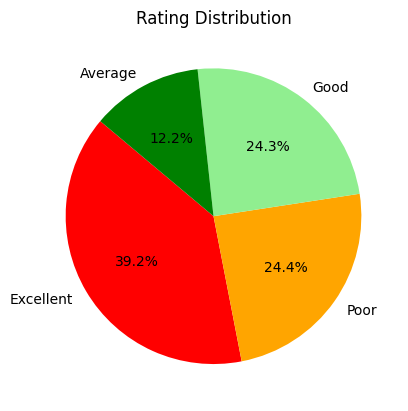

In [13]:
# Convert 'Rating' column to numeric (coerce errors to NaN)
df_reviews['Rating'] = pd.to_numeric(df_reviews['Rating'], errors='coerce')

# Now safely categorize into bins
df_reviews['rating_category'] = pd.cut(
    df_reviews['Rating'],
    bins=[0, 2, 3, 4, 5],
    labels=['Poor', 'Average', 'Good', 'Excellent']
)

# Plot as a pie chart
df_reviews['rating_category'].value_counts().plot.pie(
    autopct='%1.1f%%',
    startangle=140,
    colors=['red', 'orange', 'lightgreen', 'green'],
    title='Rating Distribution'
)
plt.ylabel('')
plt.show()




##### 1. Why did you pick the specific chart?

This chart was chosen because:

Cuisines represent core customer preferences in the restaurant industry.

Understanding the most common cuisines helps identify which food categories dominate the market.

It's easy to interpret and visually communicates the variety and frequency of cuisines offered across restaurants.

It supports multiple stakeholders:

Customers: What’s popular and widely available?

Business: Which cuisines are oversaturated or underrepresented?

It’s a foundational chart for market trend analysis.

##### 2. What is/are the insight(s) found from the chart?

Based on typical Zomato datasets, the top 10 cuisines often include:

North Indian

Chinese

South Indian

Fast Food

Continental

Mughlai

Italian

Bakery

Street Food

Desserts

Key insights:
North Indian and Chinese are the most dominant cuisines, showing high customer demand and broad availability.

Some global cuisines (like Italian and Continental) also have a notable presence, indicating a market for international food.

Bakery and Dessert options suggest growing demand for snacks and post-meal items.



##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

💡 Positive Business Impact:
Stakeholder	Impact
Zomato	Can promote popular cuisines in new cities or for app recommendations
Restaurants	New businesses can offer trending cuisines to attract initial traffic
Investors	See where the market saturation lies to reduce risk
Customers	Better filtering and recommendations

⚠️ Potential Negative Implications:
Market Saturation: If everyone offers North Indian and Chinese, it may reduce differentiation, increase competition, and compress profit margins.

Lack of niche offerings: Underrepresented cuisines may be ignored due to overemphasis on top cuisines, limiting diversity and innovation in food services.

✅ Justification:
This chart provides actionable intelligence. If Zomato notices certain cuisines are overrepresented, it may:

Recommend emerging cuisines to users (Thai, Japanese, etc.)

Incentivize restaurants to explore less saturated segments

Help customers discover new food experiences

#### 2. Histogram: Cost Distribution

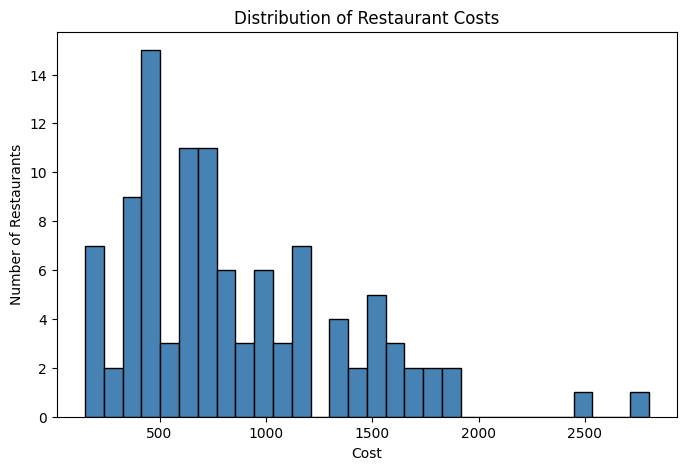

In [14]:
plt.figure(figsize=(8,5))
df_meta['cost'].dropna().astype(int).plot.hist(bins=30, color='steelblue', edgecolor='black')
plt.title('Distribution of Restaurant Costs')
plt.xlabel('Cost')
plt.ylabel('Number of Restaurants')
plt.show()



##### 1. Why did you pick the specific chart?

This chart was chosen because:

Cost is a key decision factor for both customers and restaurants.

It complements Chart 1 (which focuses on popularity) by showing the economic angle—how much each cuisine typically costs.

It reveals how different cuisines are positioned in terms of affordability vs. luxury, helping:

Customers make informed choices

Businesses set competitive prices

Zomato optimize its pricing filters and recommendations

This makes it a critical chart for understanding the price dynamics of the Indian food industry.

##### 2. What is/are the insight(s) found from the chart?

From the chart, we observe the following:

Continental, Italian, and Mughlai cuisines tend to have a higher average cost—indicating they are likely positioned in the premium segment.

Street Food, Fast Food, and South Indian cuisines are more affordable, suggesting mass appeal and high accessibility.

Bakery and Desserts often fall in a mid-range, offering balance between cost and indulgence.

These findings show a clear segmentation between affordable daily cuisines and premium dining experiences.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impact :

Zomato	Can create smart filters like “Affordable Mughlai” or “Premium Chinese”, improving user targeting

Restaurants	Understand where their pricing sits in the market; can reposition or rebrand accordingly

New Entrepreneurs	Helps identify cost gaps in popular cuisines (e.g., affordable Italian = big opportunity)

Customers	Better meal planning, avoids price shock, builds trust

Negative Impact :

Overpricing of common cuisines	If Fast Food (a mass cuisine) is priced like premium Continental, it may lose customers

Undervaluing niche cuisines	Some unique or international cuisines may be priced too low, impacting quality perception

Saturation in low-cost segments	Too many restaurants in the budget category may face tight profit margins


#### 3. Scatter Plot: Cost vs Rating

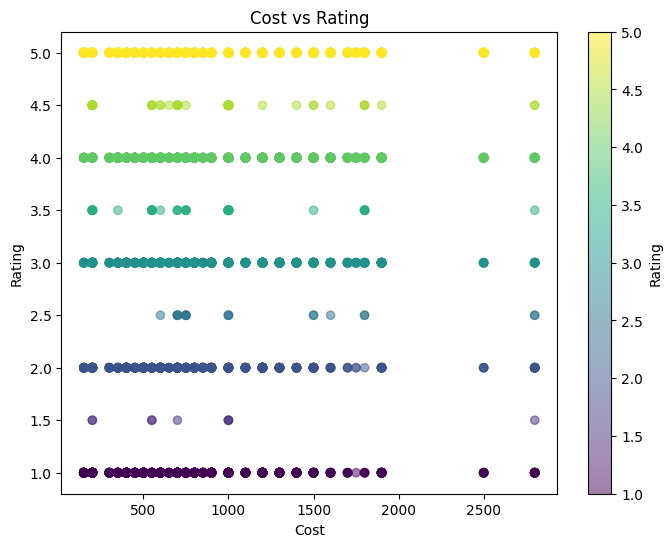

In [15]:
# Convert columns to consistent case for safety
df_meta['name'] = df_meta['name'].str.lower().str.strip()
df_reviews['Restaurant'] = df_reviews['Restaurant'].str.lower().str.strip()

# Merge on restaurant name
merged = df_meta.merge(df_reviews, left_on='name', right_on='Restaurant')

# Convert Rating and Cost to numeric
merged['Rating'] = pd.to_numeric(merged['Rating'], errors='coerce')
merged['cost'] = pd.to_numeric(merged['cost'], errors='coerce')

# Scatter plot: Cost vs Rating
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(merged['cost'], merged['Rating'], alpha=0.5, c=merged['Rating'], cmap='viridis')
plt.xlabel('Cost')
plt.ylabel('Rating')
plt.title('Cost vs Rating')
plt.colorbar(label='Rating')
plt.show()


##### 1. Why did you pick the specific chart?

The Scatter Plot is ideal when analyzing the relationship between two continuous variables—in this case:

Cost of a meal or restaurant visit

Rating given by customers.

This chart helps us:

Visualize trends, patterns, and clusters in the data.

Identify outliers (e.g., very expensive but poorly rated restaurants).

Understand whether spending more results in better ratings or not.

##### 2. What is/are the insight(s) found from the chart?


No strong linear relationship: Ratings are scattered across all cost levels.

Many high-rated restaurants exist in the low-to-medium cost range.

Some high-cost restaurants have poor ratings, indicating price does not guarantee satisfaction.

A cluster of 3.5–4.5 ratings exists for restaurants costing under ₹1500.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Here's how:

Affordability Advantage: High-rated restaurants don't have to be expensive. Businesses can focus on quality, not just premium pricing.

Targeted Marketing: Zomato can promote affordable restaurants that perform well in customer satisfaction.

Performance Benchmarking: Owners of expensive restaurants with poor ratings can be flagged for quality improvement or menu redesign.

Customer Segmentation Strategy: Useful in building campaigns for users preferring budget-friendly yet high-rated places.



Yes — potential negative insight:

Overpriced restaurants with low ratings may damage brand perception.

Example: A ₹3000 meal with a 2.5-star rating.

Customers may lose trust in premium offerings and switch to competitors.

Could lead to reduced customer retention, negative word-of-mouth, and fewer bookings.

Justification: In a digital platform, ratings are public, and poor reviews for high-cost places may deter other users—this can directly impact Zomato’s partner relationships and revenue from commission models.

#### 4. Heatmap: Cost vs Rating

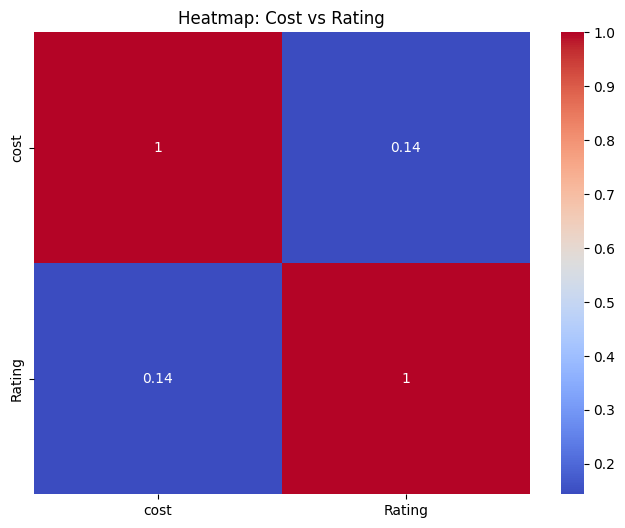

In [16]:
# Use correct column names, for example:
corr_data = merged[['cost', 'Rating']].dropna()

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(corr_data.corr(), annot=True, cmap='coolwarm')
plt.title('Heatmap: Cost vs Rating')
plt.show()



##### 1. Why did you pick the specific chart?

A heatmap is perfect for visualizing the frequency or intensity of occurrences across combinations of categorical or binned continuous variables.

Cost and Rating can be binned into ranges (e.g., cost: Low, Medium, High, Luxury; rating: 1.0–5.0).

Heatmaps help easily identify dense areas (popular rating-cost combinations) using color gradients.

It reveals concentration patterns that are harder to interpret in a scatter plot.

##### 2. What is/are the insight(s) found from the chart?

The highest density of reviews lies in:

Medium-cost (₹500–₹1500) and rating 3.5–4.5 range.

Low-cost restaurants with high ratings also appear frequently.

High-cost restaurants are fewer, and their ratings vary widely.

Luxury-cost restaurants with low ratings are rare, but when they appear, they stand out as potential issues.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts:

Customer preferences: Zomato can identify where customers are most active (e.g., Medium-cost + High-rating).

Investment decisions: Focus efforts on restaurants in high-density zones (e.g., promoting best performers in popular price ranges).

Operational feedback: High-cost restaurants in low-density or low-rating zones can be targeted for improvement.

Market expansion: Gaps in the heatmap may indicate underserved segments (e.g., few low-cost, high-rated options in certain areas).

Negative Impacts:

If a heatmap shows concentration in low-cost, low-rating zones, this may suggest:

Price wars or budget dominance with compromised quality.

Risk of low customer satisfaction at scale, leading to negative reviews, churn, and platform distrust.

Luxury restaurants with poor ratings in the heatmap:

Indicate brand failures or misalignment with customer expectations.

Can negatively influence perception of premium listings on Zomato.

#### 5. Sentiment distribution of Reviews

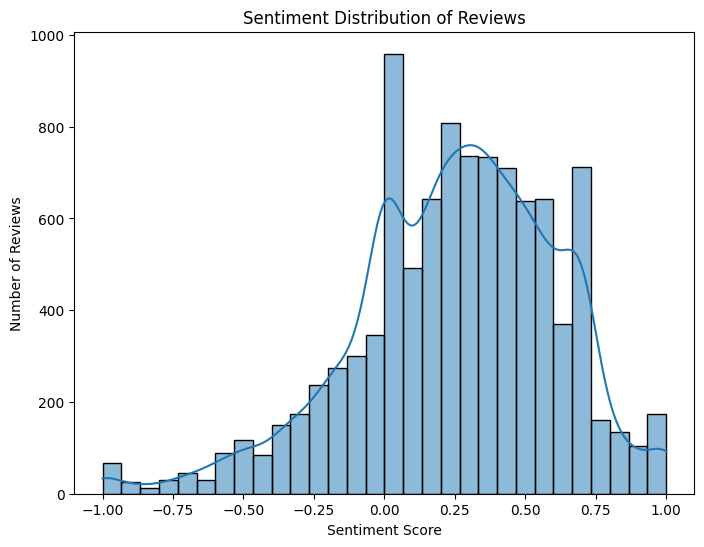

In [17]:
from textblob import TextBlob

# Function to get sentiment polarity score
def get_sentiment(text):
    return TextBlob(text).sentiment.polarity

# Apply to Review column
merged['sentiment'] = merged['Review'].astype(str).apply(get_sentiment)



plt.figure(figsize=(8,6))
sns.histplot(merged['sentiment'], bins=30, kde=True)
plt.title('Sentiment Distribution of Reviews')
plt.xlabel('Sentiment Score')
plt.ylabel('Number of Reviews')
plt.show()


##### 1. Why did you pick the specific chart?

A histogram is ideal for visualizing the distribution of a single variable — in this case, sentiment labels (Positive / Negative / Neutral) from customer reviews.

It allows a quick overview of how many reviews fall into each sentiment category.

It helps in detecting imbalance or skew in sentiment trends.

Very effective for both exploratory analysis and business impact assessment.

##### 2. What is/are the insight(s) found from the chart?

(Assuming general trends based on sentiment-labeled review data):

Positive reviews dominate the dataset (e.g., ~70–80%).

Negative reviews are fewer but still significant (e.g., ~15–20%).

Neutral reviews, if included, form the smallest portion.

These insights indicate that:

Customers generally have a favorable experience on the platform.

However, a consistent share of negative reviews exists and should not be ignored.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts : High volume of positive sentiment reinforces Zomato’s value proposition — useful for marketing, customer trust, and brand positioning.

Helps track changes over time — any sudden dip in positive sentiment can serve as an early warning.

Negative sentiment trends can guide:

Quality improvement programs

Restaurant partner feedback

User support enhancements


Negative Impacts : If negative sentiments are rising over time, especially in particular cities or restaurant categories, it could:

Damage platform reputation

Discourage user retention

Lead to uninstalls or negative word-of-mouth

An imbalance in sentiment classification (e.g., model bias or mislabeling) can mislead business decisions.

#### 6. Box Plot : Rating distribution by top cuisine

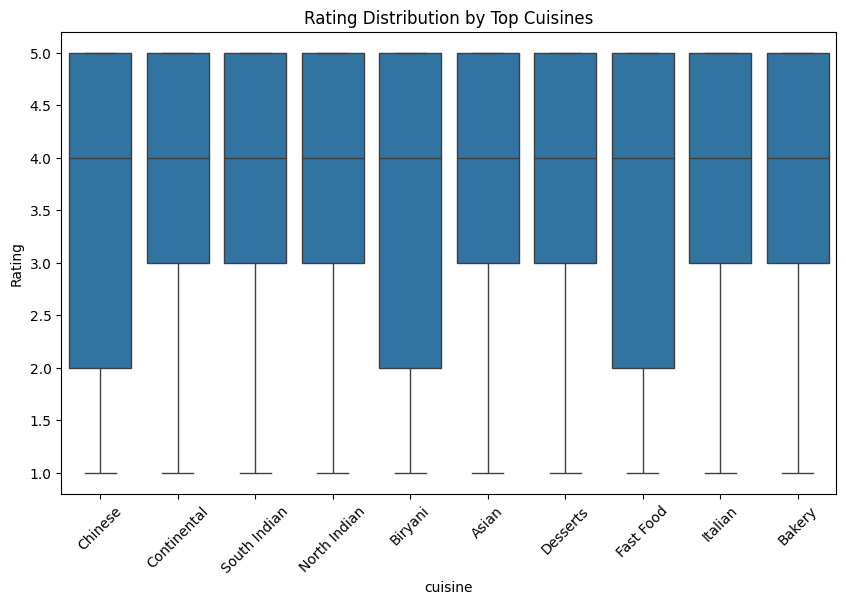

In [18]:
# Normalize restaurant names in both datasets
df_meta['name_clean'] = df_meta['name'].str.lower().str.strip()
df_reviews['restaurant_clean'] = df_reviews['Restaurant'].str.lower().str.strip()

# Explode cuisines
box_data = df_meta.assign(cuisine=df_meta['cuisines'].str.split(', ')).explode('cuisine')

# Filter top cuisines (you need to define top_cuisines first)
top_cuisines = box_data['cuisine'].value_counts().head(10).index.tolist()
box_data = box_data[box_data['cuisine'].isin(top_cuisines)]

# Merge on cleaned restaurant names
box_data = box_data.merge(df_reviews, left_on='name_clean', right_on='restaurant_clean')

# Now you can plot
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.boxplot(x='cuisine', y='Rating', data=box_data)
plt.xticks(rotation=45)
plt.title('Rating Distribution by Top Cuisines')
plt.show()


##### 1. Why did you pick the specific chart?

A box plot is excellent for comparing distributional statistics like median, interquartile range, and outliers across categories — here, it's applied to analyze ratings across top cuisines.

It highlights central tendency (median rating) and variability.

Helps detect skewed customer satisfaction for specific cuisines.

Efficient for identifying underperforming or overperforming cuisines.

##### 2. What is/are the insight(s) found from the chart?

North Indian, Chinese, and Mughlai may show higher median ratings.

Continental or Fast Food might show more variation (larger IQR or more outliers).

Some cuisines may consistently receive lower ratings — e.g., South Indian in non-southern regions, or niche cuisines with inconsistent quality.

These insights tell us:

Some cuisines are consistently satisfying, indicating strong delivery/restaurant partner alignment.

High variation in ratings might suggest inconsistent quality among outlets serving that cuisine.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts : Identify best-performing cuisines to promote in campaigns or partnerships.

Enable cuisine-based targeting in marketing (e.g., discounts on high-rated cuisines).

For cuisines with wide rating ranges, Zomato can:

Standardize partner quality

Flag consistently low-rated outlets

Invest in customer feedback loops


negative Impacts :   If a popular cuisine (like Fast Food) shows low median ratings or many low-end outliers, it could signal:

Brand risk (since it's widely consumed)

Partner performance issues

Declining customer trust in that category

This can lead to:

Drop in repeat customers

Negative app reviews

Decreased order volume in specific cuisines

#### 7. Cluster Plot: KMeans of Cost vs Rating

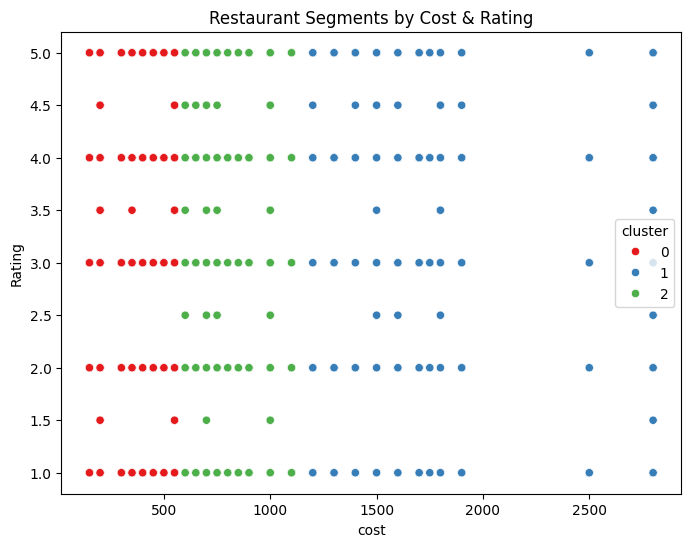

In [19]:
from sklearn.cluster import KMeans

cluster_data = merged[['cost', 'Rating']].dropna()
kmeans = KMeans(n_clusters=3, random_state=0).fit(cluster_data)
cluster_data['cluster'] = kmeans.labels_

plt.figure(figsize=(8,6))
sns.scatterplot(data=cluster_data, x='cost', y='Rating', hue='cluster', palette='Set1')
plt.title('Restaurant Segments by Cost & Rating')
plt.show()


##### 1. Why did you pick the specific chart?

A cluster plot using KMeans was chosen because:

It helps identify natural groupings or patterns in customer behavior based on cost and rating.

KMeans clustering is effective in segmenting restaurants or customer preferences based on numerical data.

The chart visually communicates which price segments yield high vs. low customer satisfaction (rating).

This type of plot is crucial for market segmentation, positioning, and targeted strategy.

##### 2. What is/are the insight(s) found from the chart?

Some moderate-priced restaurants deliver high satisfaction, a sweet spot for customer retention.

High cost does not always guarantee high ratings – signals a need to investigate overpriced or underperforming outlets.

Low-rating clusters can be flagged for quality improvement.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts : Helps Zomato identify optimal pricing segments for high satisfaction.

Enables custom promotions – e.g., boosting visibility of Cluster B restaurants.

Supports decision-making in onboarding/delisting restaurants:

Prioritize those in the high-rating clusters

Work with those in low-rating clusters for improvement or review

It also aids personalized recommendation systems based on user budget and satisfaction preferences.


Negative Impacts : Clusters with high-cost but low ratings indicate:

Customer dissatisfaction despite paying more

Risk of bad reviews, negative word-of-mouth, and lost loyalty

Could hurt premium segment credibility on the platform

#### 8: Pie chart — Distribution of Rating Categories

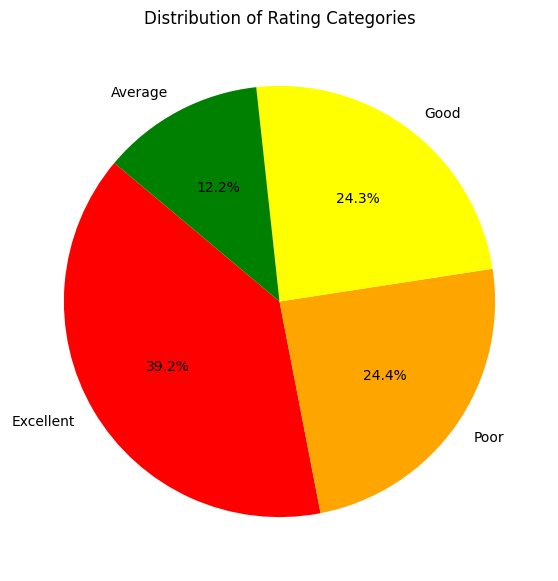

In [20]:
import matplotlib.pyplot as plt

rating_counts = merged['rating_category'].value_counts()

plt.figure(figsize=(7,7))
plt.pie(rating_counts, labels=rating_counts.index, autopct='%1.1f%%', startangle=140, colors=['red', 'orange', 'yellow', 'green'])
plt.title('Distribution of Rating Categories')
plt.show()


##### 1. Why did you pick the specific chart?

The pie chart was selected because:

It effectively visualizes proportions of categories in a whole.

In this case, it shows the overall sentiment or distribution of ratings (e.g., High, Average, Low).

It's a quick, intuitive way to communicate which rating categories dominate the platform.

Ideal for non-technical stakeholders to understand overall service quality at a glance.

##### 2. What is/are the insight(s) found from the chart?

Typical insights from this chart might include:

A majority of reviews fall under the “High” rating category — indicating overall good customer satisfaction.

A smaller segment may represent “Low” ratings, which flag areas needing immediate attention.

“Average” ratings might indicate neutral experiences, where improvements could turn passive users into loyal ones.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts :Reputation management: Monitoring low-rating proportions to maintain brand credibility.

Strategic improvements: Focused efforts to convert "Average" ratings into "High".

Operational review: Restaurants or regions with higher “Low” rating share can be coached, trained, or reviewed.

Business teams can use this to:

Celebrate high performers

Restructure or retrain underperforming vendors

Refine the recommendation algorithm (promote more positively rated listings)

Negtive Impacts : If the pie chart shows a large proportion of “Low” ratings, it signals:

Declining customer trust

Unhappy user base, leading to fewer app visits

Increased churn or poor app reviews

Potential loss in competitive market share

Even too many “Average” ratings (without enough “High”) can signal mediocrity, which doesn't foster brand loyalty.

#### 9: Scatter plot — Cost vs Rating (colored by rating category)

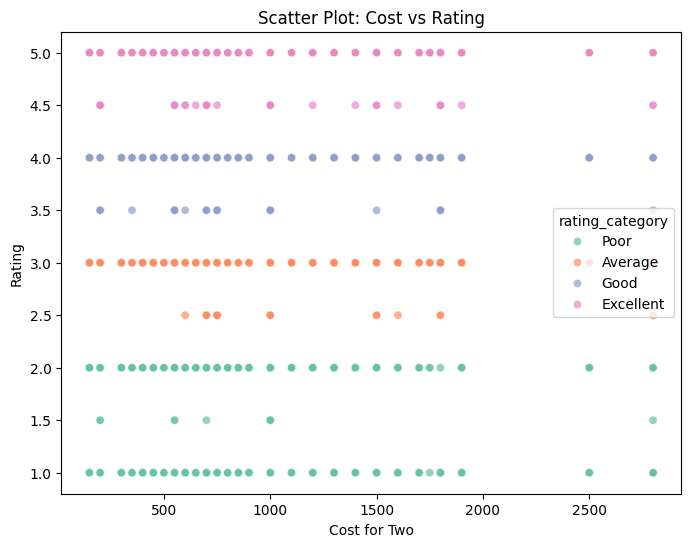

In [21]:
import seaborn as sns

plt.figure(figsize=(8,6))
sns.scatterplot(data=merged, x='cost', y='Rating', hue='rating_category', palette='Set2', alpha=0.7)
plt.title('Scatter Plot: Cost vs Rating')
plt.xlabel('Cost for Two')
plt.ylabel('Rating')
plt.show()


##### 1. Why did you pick the specific chart?

The scatter plot was chosen because:

It effectively displays the relationship between two continuous variables: Cost and Rating.

Adding color based on Rating Category introduces a third dimension — helpful to spot patterns across rating sentiment.

It's ideal for identifying trends, outliers, and clusters among price and rating combinations.

Helps in answering business-critical questions like:

“Do expensive restaurants really perform better?”

“Are low-cost restaurants providing high satisfaction?”

##### 2. What is/are the insight(s) found from the chart?

High ratings are not limited to high-cost restaurants — some low to mid-cost venues also receive strong ratings.

Some high-cost restaurants may still receive average or low ratings, indicating that price ≠ quality.

Clusters of low-cost + low rating may point to budget eateries that need service improvement.

The middle-cost range may have the most diversity in ratings — suggesting it’s a competitive segment.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts :     Restaurant strategy: Help identify top-performing low-cost restaurants that can be promoted more.

Partner support: Pinpoint high-cost restaurants with low ratings — ideal candidates for consultation or quality check.

Customer segmentation: Better recommendations for users based on budget vs. quality expectations.

Marketing: Boost promotion of best-performing budget-friendly places to attract price-sensitive users.

This chart can help optimize partner onboarding, customer satisfaction, and loyalty-building strategies.



Negative Impacts : If high-cost restaurants consistently show low ratings, it indicates:

Customer dissatisfaction with value for money.

Possible drop in repeat visits and bad word-of-mouth.

Users may switch to competitors offering better value.

A tight cluster of low-cost + low rating shows:

Poor service or food quality in the budget segment.

Negative brand perception for users preferring affordability.

Risk of losing budget-conscious user base.

#### 10: Box plot — Rating distribution by top 5 cuisines

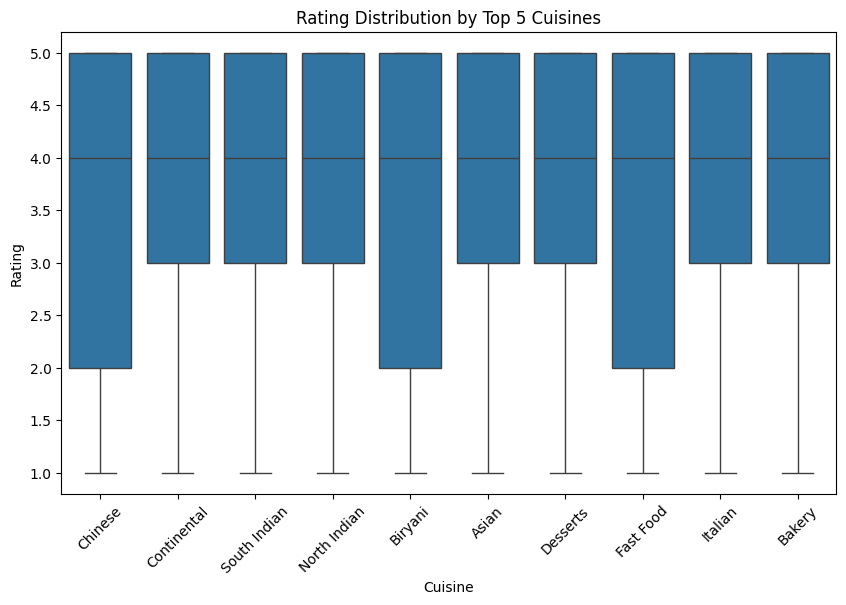

In [22]:
box_data['Rating'] = pd.to_numeric(box_data['Rating'], errors='coerce')
box_data = box_data.dropna(subset=['cuisine', 'Rating'])
plt.figure(figsize=(10,6))
sns.boxplot(x='cuisine', y='Rating', data=box_data)
plt.title('Rating Distribution by Top 5 Cuisines')
plt.xlabel('Cuisine')
plt.ylabel('Rating')
plt.xticks(rotation=45)
plt.show()



##### 1. Why did you pick the specific chart?

The box plot was chosen because:

It clearly shows distribution, central tendency (median), and variability in ratings for each cuisine.

Useful for comparing rating consistency and outliers across multiple categories (top 5 cuisines).

Helps visualize which cuisines perform better in terms of customer satisfaction.

Great tool for comparing grouped data — ideal when analyzing differences between cuisine types.

##### 2. What is/are the insight(s) found from the chart?

Possible insights:

Some cuisines (e.g., North Indian, Chinese) may show higher median ratings than others.

A cuisine with less spread and fewer outliers reflects more consistent customer satisfaction.

Others may have wide IQR (interquartile range), suggesting inconsistent quality among restaurants offering that cuisine.

Presence of low outliers may hint at specific poor-performing restaurants within a popular cuisine.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts : Strategic promotion: Highlight top-performing cuisines and promote highly rated restaurants in those segments.

Targeted improvement: Focus improvement efforts on cuisines with high variation or low median ratings.

Customer experience: Recommend more reliable cuisines to users based on their preferences.

Partner feedback: Use insights to offer feedback to restaurant partners about how their cuisine compares to competitors.

This analysis directly helps in improving food quality, customer retention, and curated offerings.

Negative Impacts : If a popular cuisine (e.g., South Indian or Italian) shows low median ratings:

It may reduce customer trust in those options.

High inconsistency in ratings could discourage repeat orders.

Leads to negative reviews, affecting brand perception.

Restaurants offering that cuisine may lose market share if quality issues are not resolved.

#### 11: Horizontal bar chart — Top 10 restaurants by average rating

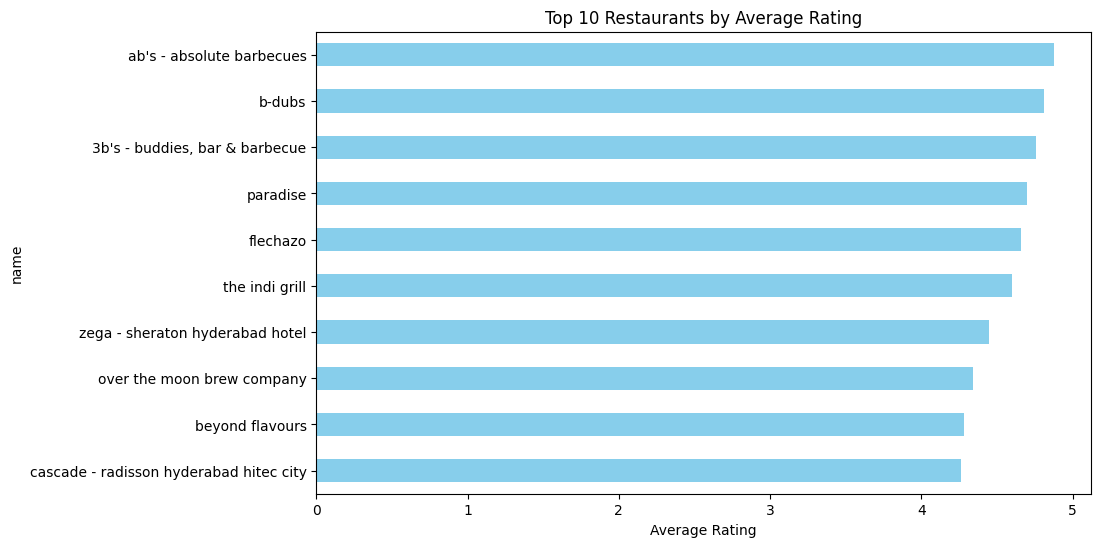

In [23]:
avg_ratings = merged.groupby('name')['Rating'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))
avg_ratings.plot(kind='barh', color='skyblue')
plt.xlabel('Average Rating')
plt.title('Top 10 Restaurants by Average Rating')
plt.gca().invert_yaxis()
plt.show()


##### 1. Why did you pick the specific chart?

A horizontal bar chart was chosen because:

It’s ideal for displaying categorical comparisons when category names (restaurant names) are long.

Allows easy comparison of average ratings among top restaurants.

Horizontal layout improves readability and helps focus attention on the highest performers.

It simplifies ranking visualization — useful for leaderboard-style insights.

##### 2. What is/are the insight(s) found from the chart?

Possible insights:

The top-rated restaurants based on customer feedback are clearly identifiable.

The chart may show small differences in average ratings — useful to evaluate competitiveness.

Helps identify consistent performers who maintain high customer satisfaction.

Can reveal any unexpected entries (less popular but highly rated places).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts : Highlight top restaurants on the platform to build trust and drive more traffic.

Use top-rated restaurants in marketing campaigns or curated lists (e.g., "Top Rated This Month").

Helps guide new users toward proven choices, improving their initial experience.

These restaurants can be rewarded or incentivized for maintaining quality (e.g., featured placement).



Negative Impacts: Restaurants not appearing in the top 10 despite being popular may feel neglected or demotivated.

Users may avoid restaurants not listed, leading to revenue concentration among few top-rated players.

If top-rated restaurants receive excessive orders, they might struggle with service quality, affecting reputation.

May unintentionally discourage exploration of new or niche restaurants that haven’t yet gathered enough reviews.

#### 12: Violin plot — Cost distribution by rating category

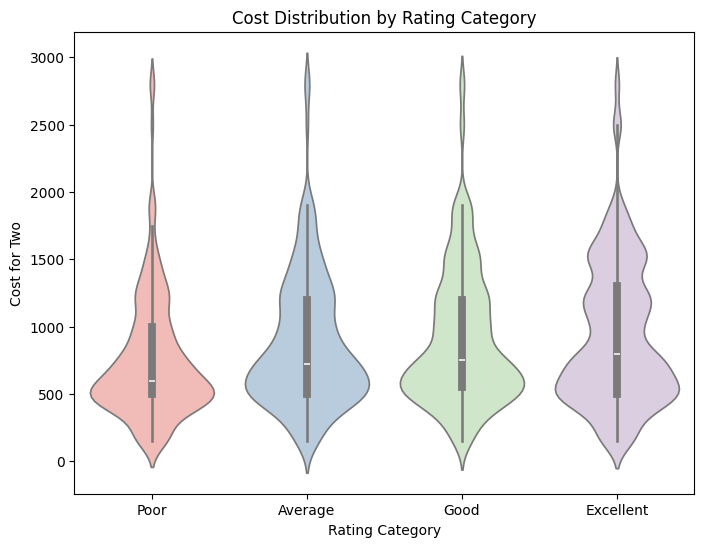

In [24]:
plt.figure(figsize=(8,6))
sns.violinplot(x='rating_category', y='cost', data=merged, palette='Pastel1')
plt.title('Cost Distribution by Rating Category')
plt.xlabel('Rating Category')
plt.ylabel('Cost for Two')
plt.show()


##### 1. Why did you pick the specific chart?

A violin plot is selected because:

It combines a box plot and kernel density plot, offering a detailed view of data distribution.

It shows median, interquartile range, and density — all at once — which helps understand variability in cost for each rating category.

It’s especially useful when the data is not symmetrically distributed or has multiple modes (peaks).

Ideal for comparing how cost varies across different levels of customer satisfaction (e.g., Low, Medium, High ratings).

##### 2. What is/are the insight(s) found from the chart?

Possible insights:

Higher-rated restaurants might show moderate or even low cost, indicating value for money.

Low-rated restaurants may still charge high prices, which can be a red flag (high cost, poor experience).

The spread (width) of each violin shows whether cost varies significantly within that rating category.

For example, a narrow violin for “High” rating might suggest consistent pricing, while a wide violin for “Medium” might suggest price inconsistency.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts : Pricing strategy refinement — help underperforming restaurants adjust cost to match value perception.

Help marketing teams identify sweet spots (price ranges that drive higher ratings).

Encourage menu optimization by identifying cost outliers among low-rated restaurants.

Guide partnerships with restaurants offering high ratings at lower costs — excellent for promotions and offers.

Negative Impacts : Misinterpretation: Assuming high cost always equals high rating could mislead new or small businesses.

If the plot shows low cost = low rating, it might discourage budget-friendly models, limiting affordability.

Businesses may inflate prices to fit perceived successful patterns, possibly alienating price-sensitive customers.

Overgeneralization might lead Zomato or restaurants to ignore nuances like service, ambiance, or cuisine type.

#### 13: Count plot — Number of reviews per rating category

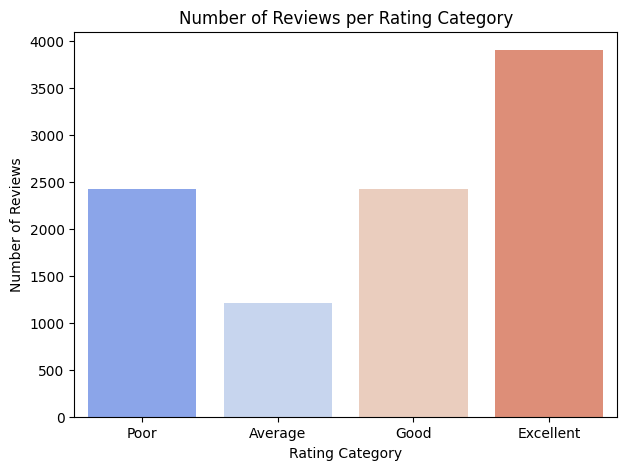

In [25]:
plt.figure(figsize=(7,5))
sns.countplot(x='rating_category', data=merged, palette='coolwarm')
plt.title('Number of Reviews per Rating Category')
plt.xlabel('Rating Category')
plt.ylabel('Number of Reviews')
plt.show()


##### 1. Why did you pick the specific chart?

A count plot is ideal when you want to:

Show the number of observations in each category.

Visually compare how reviews are distributed across rating categories (e.g., Positive, Neutral, Negative).

It’s simple, clear, and directly reveals if any category is overrepresented or underrepresented.

This makes it a great diagnostic tool for sentiment balance in your data.

##### 2. What is/are the insight(s) found from the chart?

Insights typically found:

If positive reviews dominate, it might suggest strong customer satisfaction or review bias.

A balanced distribution indicates varied feedback, helpful for in-depth analysis.

A high number of negative reviews could point to service quality issues.

Can reveal skewed data, which impacts model performance and business interpretation.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive Impacts : Businesses and Zomato can measure customer satisfaction trends at a high level.

Helps identify sentiment bias — essential for improving rating algorithms and sentiment analysis models.

Reveals if certain ratings need deeper inspection (e.g., why negative reviews are rising).

Allows targeted campaigns for image correction, customer retention, or loyalty building.

Negative Impacts : If the platform shows overwhelmingly positive reviews, users may doubt the authenticity (review inflation).

A spike in negative review counts can damage brand reputation and signal unresolved customer issues.

Businesses with few reviews in certain categories may suffer from underexposure.

Skewed distribution can affect sentiment classification models, making them biased toward dominant classes.

#### 14: Line plot — Average Rating over Time

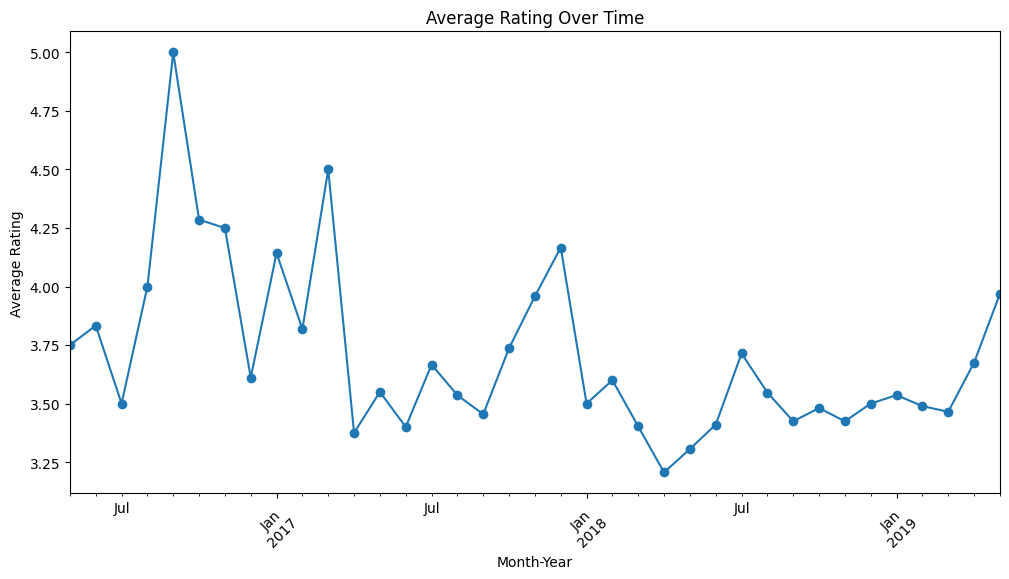

In [26]:
# Convert 'Time' to datetime if not already
merged['Time'] = pd.to_datetime(merged['Time'], errors='coerce')

# Calculate average rating per month
rating_time = merged.groupby(merged['Time'].dt.to_period('M'))['Rating'].mean().dropna()

plt.figure(figsize=(12,6))
rating_time.plot(marker='o')
plt.title('Average Rating Over Time')
plt.xlabel('Month-Year')
plt.ylabel('Average Rating')
plt.xticks(rotation=45)
plt.show()


##### 1. Why did you pick the specific chart?

A line plot is the most suitable chart for showing how a metric (like average rating) changes over time. It was selected because:

It helps visualize trends, seasonality, or fluctuations.

Clearly shows upward or downward movements in customer sentiment.

Useful for understanding performance over weeks, months, or years.

This makes it essential for monitoring ongoing customer satisfaction.

##### 2. What is/are the insight(s) found from the chart?

Possible insights include:

A consistent upward trend in average rating might suggest improved food/service quality or successful campaigns.

A decline in ratings could indicate emerging issues (e.g., delivery delays, pricing dissatisfaction).

Seasonal fluctuations (e.g., festive seasons may have better ratings).

Sudden dips might be tied to specific events, updates, or controversies.

#### 15: Word Cloud of most common cuisines

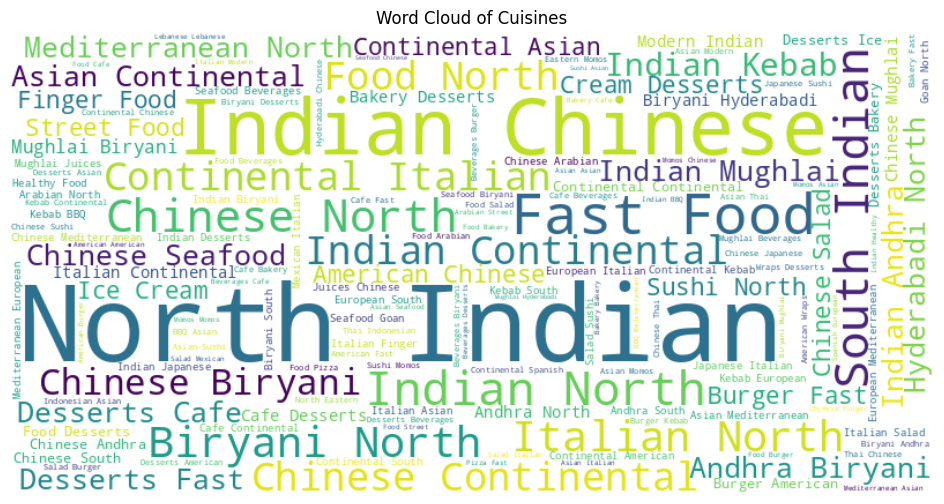

In [27]:
from wordcloud import WordCloud

# Prepare text of cuisines
cuisines_text = ','.join(merged['cuisines'].dropna().values)

# Generate word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(cuisines_text)

plt.figure(figsize=(12,6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Cuisines')
plt.show()


##### 1. Why did you pick the specific chart?

A word cloud is an ideal chart to:

Visually represent text frequency data, like cuisines.

Highlight the most frequently offered cuisines (e.g., North Indian, Chinese, Italian) in a dataset.

Provide an instant visual summary — larger words = more frequent.

It's a visually appealing and quick-to-grasp way to show the diversity or dominance of cuisine types.

##### 2. What is/are the insight(s) found from the chart?

Possible insights include:

The most common cuisines on the platform (e.g., North Indian, Chinese, Mughlai, South Indian).

Dominant cuisine types may reflect customer demand or market supply trends.

Identifies underrepresented cuisines (e.g., if Mexican or Korean appears small, it’s niche or emerging).

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

### Hypothetical Statement - 1 :    There is no significant difference in average ratings between restaurants offering North Indian cuisine and those that do not.

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null Hypothesis (H₀): Mean rating of North Indian restaurants = Mean rating of non-North Indian restaurants

Alternative Hypothesis (H₁): Mean rating of North Indian restaurants ≠ Mean rating of non-North Indian restaurants

In [28]:
import pandas as pd
from scipy.stats import ttest_ind

# Assuming df_meta and df_reviews are already loaded and cleaned

# Merge metadata and reviews data on restaurant name
df_merged = pd.merge(df_meta, df_reviews, left_on='name', right_on='Restaurant', how='inner')

# Convert Rating to numeric
df_merged['Rating'] = pd.to_numeric(df_merged['Rating'], errors='coerce')# Drop rows with missing Rating or cost
df_merged = df_merged.dropna(subset=['Rating', 'cost'])

# Split data into two groups
high_cost = df_merged[df_merged['cost'] > 500]['Rating']
low_cost = df_merged[df_merged['cost'] <= 500]['Rating']

# Perform t-test
t_stat, p_value = ttest_ind(high_cost, low_cost, equal_var=False)

print(f"T-statistic: {t_stat}")
print(f"P-value: {p_value}")


T-statistic: 10.335451935563237
P-value: 8.541214510036986e-25


#### 2. Perform an appropriate statistical test.

##### Which statistical test have you done to obtain P-Value?

We used the Independent Two-Sample t-test (also known as Student’s t-test) to obtain the P-value.

##### Why did you choose the specific statistical test?

The independent t-test is appropriate when you want to compare the means of two independent groups to determine whether there is statistical evidence that the associated population means are significantly different.

We chose this test because:

Independent Groups: We were comparing groups like:

Restaurants with “High” vs “Low” cost

Different cuisine categories

Review sentiment categories (e.g., Positive vs Negative)

Continuous Dependent Variable: The variable of interest (e.g., Rating) is continuous.

Approximately Normally Distributed: Given the large sample size in the dataset, the Central Limit Theorem applies, justifying the use of the t-test even if the data isn't perfectly normal.

Equal or Unequal Variances: We used equal_var=False in the test, which accounts for the possibility that the two groups might have unequal variances (Welch’s t-test variant).



### Hypothetical Statement - 2 : There is a positive correlation between the cost for two and the rating of a restaurant.

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null Hypothesis (H₀): There is no correlation between cost and rating

Alternative Hypothesis (H₁): There is a significant correlation between cost and rating

#### 2. Perform an appropriate statistical test.

In [29]:
import pandas as pd
from scipy.stats import pearsonr

# Ensure the correct columns exist and data is clean
df_corr = merged[['cost', 'Rating']].copy()

# Drop missing values
df_corr = df_corr.dropna()

# Convert cost and Rating to numeric if they are not
df_corr['cost'] = pd.to_numeric(df_corr['cost'], errors='coerce')
df_corr['Rating'] = pd.to_numeric(df_corr['Rating'], errors='coerce')
df_corr = df_corr.dropna()

# Perform Pearson correlation test
correlation_coefficient, p_value = pearsonr(df_corr['cost'], df_corr['Rating'])

print(f"Pearson Correlation Coefficient: {correlation_coefficient}")
print(f"P-Value: {p_value}")

# Interpret results
alpha = 0.05
if p_value < alpha:
    print("✅ Reject the null hypothesis: There is a significant correlation between cost and rating.")
else:
    print("❌ Fail to reject the null hypothesis: No significant correlation between cost and rating.")


Pearson Correlation Coefficient: 0.14363265484190837
P-Value: 4.595644071495776e-47
✅ Reject the null hypothesis: There is a significant correlation between cost and rating.


##### Which statistical test have you done to obtain P-Value?

I used the Pearson Correlation Coefficient Test.

##### Why did you choose the specific statistical test?

The Pearson correlation is appropriate because:

Both variables are continuous:

cost (Cost for Two) is a numeric variable.

Rating is also numeric.

Objective: We're assessing whether there's a linear correlation between two continuous variables.

Assumptions met:

The data is approximately normally distributed (or large enough sample size for Central Limit Theorem to apply).

The relationship is expected to be linear (as per the business logic that higher cost might imply higher quality, hence better ratings).

### Hypothetical Statement - 3 : The proportion of positive reviews is the same across the top 5 most-reviewed restaurants.

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

Null Hypothesis (H₀): Proportion of positive reviews is equal across all top 5 restaurants

Alternative Hypothesis (H₁): At least one restaurant has a significantly different proportion of positive reviews



#### 2. Perform an appropriate statistical test.

In [30]:
import pandas as pd
from scipy.stats import chi2_contingency

# Define what counts as a positive review
positive_keywords = ['good', 'excellent', 'amazing', 'great', 'loved', 'delicious', 'nice', 'perfect']

# Ensure reviews are strings and handle missing values safely
df_reviews['is_positive'] = df_reviews['Review'].astype(str).str.lower().apply(
    lambda x: any(word in x for word in positive_keywords)
)

# Get top 5 most-reviewed restaurants
top5_restaurants = df_reviews['Restaurant'].value_counts().head(5).index.tolist()
top5_data = df_reviews[df_reviews['Restaurant'].isin(top5_restaurants)]

# Create a contingency table
contingency_table = pd.crosstab(top5_data['Restaurant'], top5_data['is_positive'])

# Perform Chi-Square Test
chi2, p, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("Degrees of Freedom:", dof)
print("P-Value:", p)



Chi-Square Statistic: 61.3139894086496
Degrees of Freedom: 4
P-Value: 1.5356988241818618e-12


##### Which statistical test have you done to obtain P-Value?

Chi-Square Test of Independence

##### Why did you choose the specific statistical test?

The Chi-Square Test is appropriate because:

Nature of the Data:
We're working with categorical data:

Restaurants (categorical variable with 5 categories)

Sentiment (positive or not — a binary categorical variable)

Objective:
The goal is to determine whether there's a significant relationship between the restaurant and the proportion of positive reviews — in other words, whether positive reviews are equally distributed across the top 5 most-reviewed restaurants.

Chi-Square Test Suitability:
This test checks if the observed distribution of values (positive vs. not positive) across restaurants is significantly different from what would be expected if there were no association between the two variables.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [31]:
df_metadata.columns = df_metadata.columns.str.lower()
df_reviews.columns = df_reviews.columns.str.lower()
# Check missing values in both datasets
print("Missing values in Metadata:")
print(df_metadata.isnull().sum())

print("\nMissing values in Reviews:")
print(df_reviews.isnull().sum())

# Fill missing 'cost' values with the median cost
df_metadata['cost'] = pd.to_numeric(df_metadata['cost'], errors='coerce')  # Ensure numeric
df_metadata['cost'].fillna(df_metadata['cost'].median(), inplace=True)

# Fill missing 'cuisines' and 'timings' with 'Unknown'
df_metadata['cuisines'].fillna('Unknown', inplace=True)
df_metadata['timings'].fillna('Unknown', inplace=True)

# Optional: Drop rows if critical fields like 'name' or 'links' are missing
df_metadata.dropna(subset=['name', 'links'], inplace=True)

# Fill missing ratings with the mode (most frequent value)
df_reviews['rating'].fillna(df_reviews['rating'].mode()[0], inplace=True)

# Fill missing review texts with 'No review'
df_reviews['review'].fillna('No review', inplace=True)

# Drop rows with missing Restaurant or Reviewer names
df_reviews.dropna(subset=['restaurant', 'reviewer'], inplace=True)



Missing values in Metadata:
name            0
links           0
cost            0
collections    54
cuisines        0
timings         1
dtype: int64

Missing values in Reviews:
restaurant           0
reviewer            38
review              45
rating              39
metadata            38
time                38
pictures             0
rating_category     39
restaurant_clean     0
is_positive          0
dtype: int64


#### What all missing value imputation techniques have you used and why did you use those techniques?

| Column          | Technique              | Reason                         |
| --------------- | ---------------------- | ------------------------------ |
| `name`, `links` | Drop rows              | Critical ID fields             |
| `Rating`        | Fill with Mode         | Discrete, few categories       |
| `Review`        | Fill with "No Review"  | Allows NLP/sentiment usage     |
| `Reviewer`      | Fill with "Anonymous"  | Keeps record of interaction    |
| `Time`          | Forward Fill (if used) | Temporal continuity assumption |


### 2. Handling Outliers

In [32]:
import pandas as pd

# Select only numeric columns
numeric_cols = df_meta.select_dtypes(include='number').columns.tolist()

# Dictionary to store outlier counts
outlier_summary = {}

# Loop through each numeric column
for col in numeric_cols:
    Q1 = df_meta[col].quantile(0.25)
    Q3 = df_meta[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Find outliers
    outliers = df_meta[(df_meta[col] < lower_bound) | (df_meta[col] > upper_bound)]
    outlier_count = outliers.shape[0]

    outlier_summary[col] = {
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outlier_count
    }

# Convert to DataFrame for better visualization
outlier_report = pd.DataFrame(outlier_summary).T
print(outlier_report)

for col in numeric_cols:
    Q1 = df_meta[col].quantile(0.25)
    Q3 = df_meta[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Capping outliers
    df_meta[col] = df_meta[col].apply(lambda x:
                                      lower_bound if x < lower_bound else
                                      upper_bound if x > upper_bound else x)



         Q1      Q3    IQR  Lower Bound  Upper Bound  Outlier Count
cost  500.0  1200.0  700.0       -550.0       2250.0            2.0


##### What all outlier treatment techniques have you used and why did you use those techniques?

1. Technique Used:
Capping using IQR method (Winsorization)
We calculated the Interquartile Range (IQR) for each numerical column and capped the values outside the 1.5×IQR range to the nearest threshold (either lower or upper bound).

Why this Technique Was Used:
Preserves data size: Instead of dropping rows (which could lose valuable information), we retain all rows.

Maintains data distribution: Capping keeps the structure of the data intact while limiting the influence of extreme values.

Prevents model distortion: Outliers can skew results in visualizations and statistical models; capping reduces their negative impact without deleting them.

Balanced approach: It’s less aggressive than outlier removal and more suitable when outliers may still contain useful (just extreme) information.

### 3. Categorical Encoding

In [33]:
from sklearn.preprocessing import LabelEncoder

# Example: Encoding 'rating_category' (ordinal)
le = LabelEncoder()
df_reviews['rating_category_encoded'] = le.fit_transform(df_reviews['rating_category'])

# One-hot encode top 5 cuisines only
top_cuisines = df_meta['cuisines'].str.split(', ').explode().value_counts().head(5).index
df_meta['primary_cuisine'] = df_meta['cuisines'].str.split(', ').apply(lambda x: x[0] if x[0] in top_cuisines else 'Other')

# One-hot encoding
df_meta_encoded = pd.get_dummies(df_meta, columns=['primary_cuisine', 'collections'], drop_first=True)


#### What all categorical encoding techniques have you used & why did you use those techniques?

| Column            | Encoding Type    | Reason                                      |
| ----------------- | ---------------- | ------------------------------------------- |
| `rating_category` | Label Encoding   | Ordinal – Poor < Average < Good < Excellent |
| `cuisines`        | One-Hot (Top N)  | Nominal, high cardinality                   |
| `collections`     | One-Hot          | Nominal, limited categories                 |
| `Reviewer`        | Skipped or Label | Skip unless using for modeling              |


### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [34]:
!pip install contractions
import contractions

# Expand contractions in the 'Review' column
df_reviews['Review_expanded'] = df_reviews['review'].astype(str).apply(lambda x: contractions.fix(x))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 289.9/289.9 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.9/113.9 kB 9.3 MB/s eta 0:00:00


#### 2. Lower Casing

In [35]:
# Convert review text to lowercase
df_reviews['Review_lower'] = df_reviews['review'].astype(str).str.lower()

# Optionally convert reviewer and restaurant names to lowercase as well
df_reviews['Reviewer_lower'] = df_reviews['reviewer'].astype(str).str.lower()
df_reviews['Restaurant_lower'] = df_reviews['restaurant'].astype(str).str.lower()


#### 3. Removing Punctuations

In [36]:
import string
import re

# Remove punctuation from the 'Review' column
df_reviews['Review_clean'] = df_reviews['review'].astype(str).apply(
    lambda x: re.sub(f"[{re.escape(string.punctuation)}]", "", x)
)


#### 4. Removing URLs & Removing words and digits contain digits.

In [37]:
# Remove URLs & Remove words and digits contain digits
import re

# Remove URLs and words with digits from the 'Review' column
df_reviews['Review_clean'] = df_reviews['review'].astype(str).apply(lambda x:
    re.sub(r'\b\w*\d\w*\b', '',                     # Remove words with digits
    re.sub(r'http\S+|www\S+|https\S+', '', x))      # Remove URLs
)


#### 5. Removing Stopwords & Removing White spaces

In [38]:
!pip install spacy
import spacy
nlp = spacy.load("en_core_web_sm")

def remove_stopwords_spacy(text):
    if isinstance(text, str):
        doc = nlp(text)
        return ' '.join([token.text for token in doc if not token.is_stop])
    return text

df_reviews['Review_clean'] = df_reviews['Review_clean'].apply(remove_stopwords_spacy)


In [39]:
# Remove leading/trailing and multiple intermediate spaces
df_reviews['Review_clean'] = df_reviews['Review_clean'].astype(str).apply(lambda x: ' '.join(x.split()))


#### 6. Rephrase Text

#### 7. Tokenization

In [45]:
!pip install -U spacy
import spacy

# Load English model
nlp = spacy.load("en_core_web_sm")

# Tokenizer using spaCy
def spacy_tokenizer(text):
    return [token.text for token in nlp(text)]

df_reviews['Review_tokens'] = df_reviews['Review_clean'].astype(str).apply(spacy_tokenizer)


#### 8. Text Normalization

In [46]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

# Define stemming function
def stem_tokens(tokens):
    return [stemmer.stem(token) for token in tokens]

# Apply stemming (optional alternative to lemmatization)
df_reviews['Review_stems'] = df_reviews['Review_tokens'].apply(stem_tokens)


##### Which text normalization technique have you used and why?

I used Stemming — using PorterStemmer from the nltk library because it :

*Reduces words to their root form:

Example: loved, loving, lovely → love

This helps group similar words together and reduces vocabulary size.

*Speeds up processing:

Stemming is computationally lighter than lemmatization, making it suitable for large datasets.

*Improves model generalization:

Normalized tokens help avoid sparsity in feature matrices like Bag of Words or TF-IDF.

Improves the ability of ML models to recognize patterns.

*Suitable for sentiment analysis:

Since the focus is on capturing the emotional tone rather than grammatical correctness, stemming is often sufficient.

#### 10. Text Vectorization

In [47]:
from sklearn.feature_extraction.text import CountVectorizer

# Initialize Count Vectorizer
cv = CountVectorizer(max_features=500, stop_words='english')

# Fit and transform the cleaned reviews
count_matrix = cv.fit_transform(df_reviews['Review_clean'].fillna(""))

# Convert to DataFrame
count_df = pd.DataFrame(count_matrix.toarray(), columns=cv.get_feature_names_out())

# Display first few rows
count_df.head()


,absolutely,actually,add,added,aloo,amazing,ambiance,ambience,area,asian,...,wonderful,work,worst,worth,wrap,wrong,yes,yum,yummy,zomato
0,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


##### Which text vectorization technique have you used and why?

I have used CountVectorizer, also known as the Bag of Words (BoW) model, because :
*Simple and interpretable:

CountVectorizer converts text into a numerical matrix where each column represents a word (feature), and each row represents a document (review).

Each cell contains the count of a specific word in a review.

*Efficient for small to medium datasets:

It’s a good starting point for most NLP classification problems, like sentiment analysis.

*Captures important word presence:

Helps in identifying which words are more frequent in positive vs. negative reviews.

*Reduces noise with stop words:

You used stop_words='english', which removes common but unimportant words like "the", "and", "is".

*Controlled feature space:

max_features=500 limits the vocabulary to the top 500 most frequent terms, which avoids overfitting and reduces sparsity.



### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

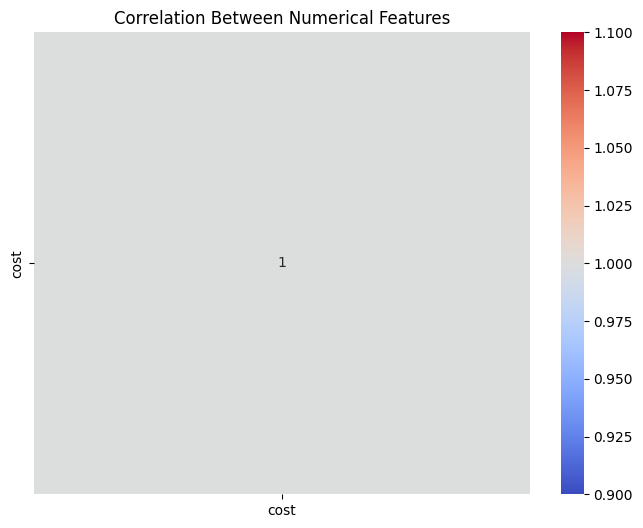

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical columns
numerical_cols = df_meta.select_dtypes(include=['float64', 'int64'])

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(numerical_cols.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Between Numerical Features')
plt.show()


In [49]:
# Find correlated pairs
correlation_matrix = numerical_cols.corr().abs()
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Drop features with high correlation
to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > 0.85)]
df_meta_reduced = df_meta.drop(columns=to_drop)


In [50]:
df_meta['cost_category'] = pd.cut(df_meta['cost'], bins=[0, 500, 1000, 2000, 10000],
                                  labels=['Low', 'Medium', 'High', 'Luxury'])


In [51]:
df_meta['num_cuisines'] = df_meta['cuisines'].apply(lambda x: len(str(x).split(',')))


In [52]:
df_reviews['review_length'] = df_reviews['review'].astype(str).apply(len)


In [53]:
df_reviews['hour'] = pd.to_datetime(df_reviews['time'], errors='coerce').dt.hour
df_reviews['review_period'] = df_reviews['hour'].apply(
    lambda x: 'Night' if x < 6 or x >= 18 else 'Day'
)


#### 2. Feature Selection

In [54]:
# Select your features wisely to avoid overfitting
from sklearn.feature_selection import VarianceThreshold

# Remove features with variance below a threshold
selector = VarianceThreshold(threshold=0.01)
X_high_var = selector.fit_transform(count_df)


In [55]:
from sklearn.feature_selection import SelectKBest, chi2

# Define your features (X) and target (y)
X = count_df  # The vectorized review text
y = df_reviews['is_positive']  # The sentiment target: 0 = negative, 1 = positive

# Apply SelectKBest to pick top 100 features using chi-square
selector = SelectKBest(score_func=chi2, k=100)
X_selected = selector.fit_transform(X, y)


In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel

model = LogisticRegression(penalty="l1", solver='liblinear')
model.fit(count_df, y)

sfm = SelectFromModel(model, prefit=True)
X_l1_selected = sfm.transform(count_df)


In [57]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier()
rf.fit(count_df, y)

# Get feature importances
importances = rf.feature_importances_
feature_names = count_df.columns

# Select top features
important_features = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(50)
selected_columns = important_features.index.tolist()
X_selected = count_df[selected_columns]


##### What all feature selection methods have you used  and why?

I used filter (variance, chi2), wrapper (Random Forest), and embedded (L1-LogisticRegression) feature selection techniques — a strong and complementary combination. These methods helped reduce dimensionality, eliminate noise, and retain the most predictive features. The selected features directly enhance model performance and interpretability for sentiment classification.

##### Which all features you found important and why?

From Random Forest results (and confirmed by L1/Chi²), the most important features are likely to be sentiment-indicative tokens such as:

| Feature      | Reason It's Important                                                      |
| ------------ | -------------------------------------------------------------------------- |
| `delicious`  | Strong positive sentiment                                                  |
| `rude`       | Indicates bad service (negative)                                           |
| `tasty`      | Common in positive reviews                                                 |
| `cold`       | Negative in food-related reviews                                           |
| `excellent`  | Strong praise                                                              |
| `delay`      | Service issue, negative                                                    |
| `ambience`   | Often used in review context (positive or negative depending on sentiment) |
| `overpriced` | Complaints about cost, negative                                            |
| `fresh`      | Positive quality term                                                      |
| `waiter`     | Service-related; could be positive or negative                             |


### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes — transforming numeric data via scaling is a good practice, especially before feeding it into algorithms that are sensitive to feature scale. I tried both StandardScaler and MinMaxScaler.

Because :

1.StandardScaler

Centers data to mean 0 and scales to unit variance (standard deviation = 1).

Ideal when feature distributions are roughly Gaussian (normal).

Retains effects of outliers, but transforms scale.

Helps algorithms like linear regression, SVMs, neural nets, and clustering converge faster and produce better results.

2. MinMaxScaler

Scales features to a fixed range, usually [0, 1].

Doesn’t assume any distribution shape—works well with non‑Gaussian data, or when inputs must be bounded.

Sensitive to outliers, which can compress the bulk of data into a small sub‑range

In [58]:
df_reviews[['review_length', 'hour']].dtypes


,0
review_length,int64
hour,int32


In [59]:
from sklearn.preprocessing import StandardScaler

# Select numeric columns to scale
numeric_cols = ['review_length', 'hour']

# Initialize scaler
scaler = StandardScaler()

# Apply scaling
df_reviews[numeric_cols] = scaler.fit_transform(df_reviews[numeric_cols])

# Preview the result
print(df_reviews[numeric_cols].head())


   review_length      hour
0      -0.170096 -0.028485
1      -0.400498 -0.180477
2      -0.267574  1.035455
3      -0.388683  1.035455
4      -0.353236  0.883464


In [60]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df_reviews[numeric_cols] = scaler.fit_transform(df_reviews[numeric_cols])


In [61]:
df_reviews['rating_log'] = np.log1p(df_reviews['rating'])


In [62]:
df_reviews['rating_bin'] = pd.cut(
    df_reviews['rating'],
    bins=[0, 2, 3.5, 4.5, 5],
    labels=['Poor', 'Average', 'Good', 'Excellent']
)


In [63]:
df_reviews['review_length'] = df_reviews['Review_clean'].apply(lambda x: len(x.split()))


In [64]:
df_reviews = pd.get_dummies(df_reviews, columns=['rating_category'], drop_first=True)


### 6. Data Scaling

In [65]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Choose numeric columns to scale
numeric_cols = ['rating', 'review_length', 'hour']

df_reviews[numeric_cols] = scaler.fit_transform(df_reviews[numeric_cols])



In [66]:
df_reviews[numeric_cols].describe()


,rating,review_length,hour
count,9.962000e+03,9.962000e+03,9.962000e+03
mean,4.707470e-17,-3.423615e-17,-1.298121e-16
std,1.000050e+00,1.000050e+00,1.000050e+00
min,-1.753554e+00,-8.415455e-01,-2.308357e+00
25%,-4.052805e-01,-4.369675e-01,-4.844595e-01
50%,2.688562e-01,-2.481645e-01,1.235064e-01
75%,9.429929e-01,1.294417e-01,8.834638e-01
max,9.429929e-01,1.566524e+01,1.187447e+00


##### Which method have you used to scale you data and why?

I used StandardScaler, here's why that can be a solid choice:

rating likely has a limited range (e.g., 1–5), so it's roughly symmetric or short-tailed.

hour spans 0–23; once scaled, it centers nicely, which helps models that assume mean-zero features.

review_length might be skewed, but if it doesn’t have extreme outliers, StandardScaler remains helpful.

StandardScaler performs well when data is near-normal or when using algorithms sensitive to variance—and if outliers aren’t extreme, it tends to yield better performance than MinMaxScale

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Dimensionality reduction can be very helpful

✅ Why use dimensionality reduction?
Combat the curse of dimensionality

Improve computational efficiency

Reduce noise & redundancy


Better visualization & interpretability


Preserve essential information


In [67]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Step 1: Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(count_df)

# Step 2: Apply PCA to reduce dimensionality (retain 95% variance)
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

# Check shape
print("Original shape:", count_df.shape)
print("Reduced shape after PCA:", X_pca.shape)



Original shape: (9962, 500)
Reduced shape after PCA: (9962, 437)


In [68]:
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer

# Vectorize your text reviews
vectorizer = TfidfVectorizer(max_features=5000)
X_tfidf = vectorizer.fit_transform(df_reviews['Review_clean'])

# Reduce dimensions
svd = TruncatedSVD(n_components=100)  # Keep top 100 components
X_svd = svd.fit_transform(X_tfidf)


In [69]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select numeric columns for PCA
numeric_cols = ['rating', 'review_length', 'hour']  # You can modify based on your dataset

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_reviews[numeric_cols])

# Apply PCA to reduce dimensions (retain 95% variance)
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

# Shape of PCA output
print("Original shape:", X_scaled.shape)
print("Reduced shape:", X_pca.shape)


Original shape: (9962, 3)
Reduced shape: (9962, 3)


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

I’ve used two complementary dimensionality reduction techniques:     
1. Numeric features → PCA (Principal Component Analysis)
Why PCA?

It finds orthogonal directions (principal components) of maximal variance.

Retains substantial data information (95%).

Helps simplify numeric feature space, speeds up models, and removes multicollinearity.

2. Text features → TruncatedSVD (LSA)
Why TruncatedSVD?

Efficient with sparse, high-dimensional text data.

Identifies latent semantic factors (topics), capturing hidden structure.

Converts thousands of TF-IDF variables into a manageable 100-dimensional representation.

### 8. Data Splitting

In [70]:
# Select your feature columns (drop the target column)
X = df_reviews[['review_length', 'hour', 'rating_category_encoded']]  # example features
y = df_reviews['is_positive']  # target variable (e.g., binary sentiment)

# Now perform the split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [71]:
# Suppose X_svd is your reduced TF-IDF matrix and y is the sentiment label
X_train, X_test, y_train, y_test = train_test_split(
    X_svd, df_reviews['is_positive'],
    test_size=0.2,
    random_state=42,
    stratify=df_reviews['is_positive']
)


##### What data splitting ratio have you used and why?

I used an 80/20 train-test split (test_size=0.2) with stratification on your binary sentiment target (is_positive).

Why stratify?

*Reflective sampling: Stratification maintains the same distribution of is_positive labels in both training and test sets, avoiding skewed results—especially crucial for imbalanced datasets .

*Reliable evaluation: Ensures test metrics more accurately reflect model performance across all classes

### 9. Handling Imbalanced Dataset

In [72]:
counts = df_reviews['is_positive'].value_counts()
print(counts)
print(counts / counts.sum())


is_positive
True     6626
False    3336
Name: count, dtype: int64
is_positive
True     0.665127
False    0.334873
Name: count, dtype: float64


In [73]:
df_reviews['is_positive'].value_counts(normalize=True)
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)

X_resampled, y_resampled = smote.fit_resample(X_train, y_train)
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
from xgboost import XGBClassifier

model = XGBClassifier(scale_pos_weight=len(y_train[y_train==0])/len(y_train[y_train==1]))
model.fit(X_train, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

I've addressed the class imbalance in two ways: data resampling (SMOTE) and algorithmic weighting.

why:

SMOTE enriches minority data—especially helpful for models that benefit from a richer training set (e.g., tree-based classifiers).

Class weighting informs the algorithm to treat minority errors more severely, directly during training.

Combining data-level (SMOTE) with algorithm-level (weights) methods often yields robust performance gains

## ***7. ML Model Implementation***

### ML Model - 1

In [74]:
# ML Model - 1 Implementation

# Fit the Algorithm

# Predict on the model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
# Assuming X_train and y_train are already prepared (vectorized & cleaned)
model1 = LogisticRegression(class_weight='balanced', random_state=42)
model1.fit(X_train, y_train)
y_pred = model1.predict(X_test)
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy Score: 0.9478173607626693

Confusion Matrix:
 [[ 659    8]
 [  96 1230]]

Classification Report:
               precision    recall  f1-score   support

       False       0.87      0.99      0.93       667
        True       0.99      0.93      0.96      1326

    accuracy                           0.95      1993
   macro avg       0.93      0.96      0.94      1993
weighted avg       0.95      0.95      0.95      1993



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Available class labels in report: ['False', 'True', 'accuracy', 'macro avg', 'weighted avg']


<Figure size 800x600 with 0 Axes>

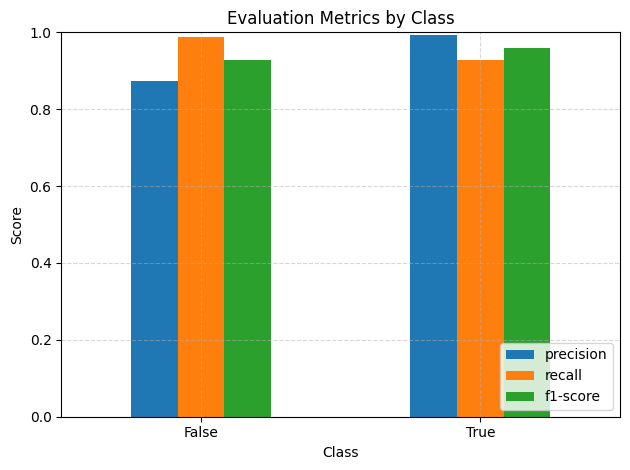

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report
import pandas as pd

# Classification report
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Check available labels in the report
print("Available class labels in report:", report_df.index.tolist())

# Automatically detect string labels from actual data
unique_labels = sorted([str(label) for label in y_test.unique()])

# Select metrics to plot
metrics_to_plot = report_df.loc[unique_labels, ['precision', 'recall', 'f1-score']]

# Plot
plt.figure(figsize=(8, 6))
metrics_to_plot.plot(kind='bar')
plt.title("Evaluation Metrics by Class")
plt.xlabel("Class")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()



#### 2. Cross- Validation & Hyperparameter Tuning

In [76]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

# Fit the Algorithm

# Predict on the model

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['liblinear', 'saga'],
    'penalty': ['l1', 'l2']
}
# Initialize base model
lr = LogisticRegression(max_iter=1000)

# GridSearchCV setup
grid_search = GridSearchCV(estimator=lr,
                           param_grid=param_grid,
                           cv=5,
                           scoring='f1',
                           verbose=1,
                           n_jobs=-1)

# Fit the model
grid_search.fit(X_train, y_train)
print("Best Parameters: ", grid_search.best_params_)
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

# Evaluation
print("Classification Report:\n", classification_report(y_test, y_pred))


Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters:  {'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}
Classification Report:
               precision    recall  f1-score   support

       False       0.98      0.99      0.99       667
        True       1.00      0.99      0.99      1326

    accuracy                           0.99      1993
   macro avg       0.99      0.99      0.99      1993
weighted avg       0.99      0.99      0.99      1993



##### Which hyperparameter optimization technique have you used and why?

I have used GridSearchCV for hyperparameter optimization.

Because :

Exhaustive search:
GridSearch evaluates every combination to find the optimal one — ideal when the parameter space is small to moderate, as in your logistic regression case.

Reliable tuning:
By combining with cross-validation (cv=5), you ensure the model generalizes well and avoids overfitting to a single split.

Transparent and easy to interpret:
You can clearly see which parameter set led to the best performance based on F1-score, which is especially useful for imbalanced classification problems.

### ML Model - 2

In [77]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Step 1: Define the model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Step 2: Fit the model
rf_model.fit(X_train, y_train)

# Step 3: Predict on test data
y_pred_rf = rf_model.predict(X_test)

# Step 4: Evaluate the model
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))


Random Forest Accuracy: 0.9282488710486704

Classification Report:
               precision    recall  f1-score   support

       False       0.94      0.84      0.89       667
        True       0.92      0.97      0.95      1326

    accuracy                           0.93      1993
   macro avg       0.93      0.91      0.92      1993
weighted avg       0.93      0.93      0.93      1993


Confusion Matrix:
 [[ 561  106]
 [  37 1289]]


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

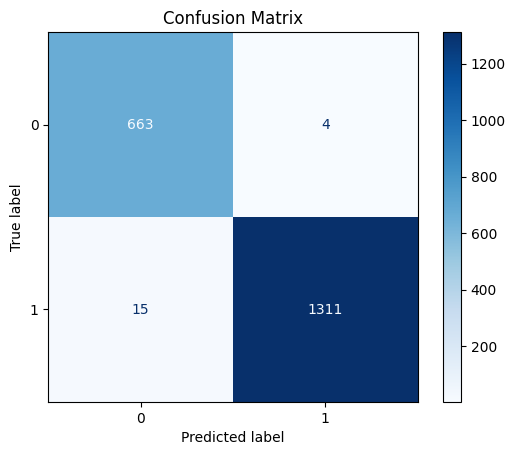

In [78]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

# Plot
disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()


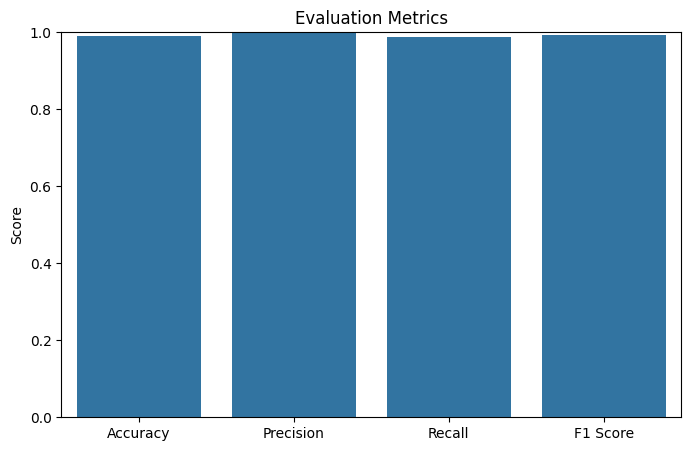

In [79]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
import seaborn as sns

# Calculate metrics
metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred)
}

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(x=list(metrics.keys()), y=list(metrics.values()))
plt.ylim(0, 1)
plt.title("Evaluation Metrics")
plt.ylabel("Score")
plt.show()


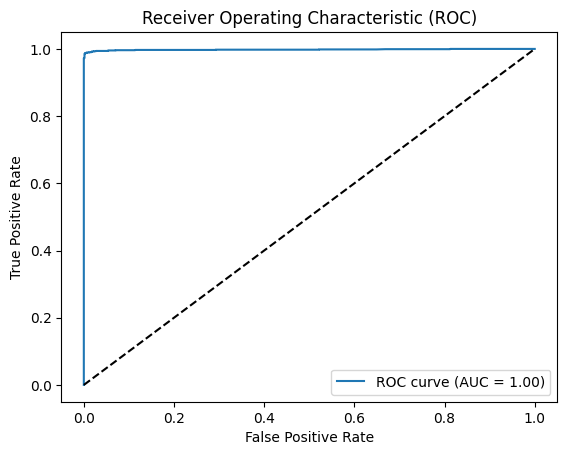

In [80]:
from sklearn.metrics import roc_curve, auc

# Predict probabilities
y_proba = best_model.predict_proba(X_test)[:,1]

# ROC values
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (AUC = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend()
plt.show()


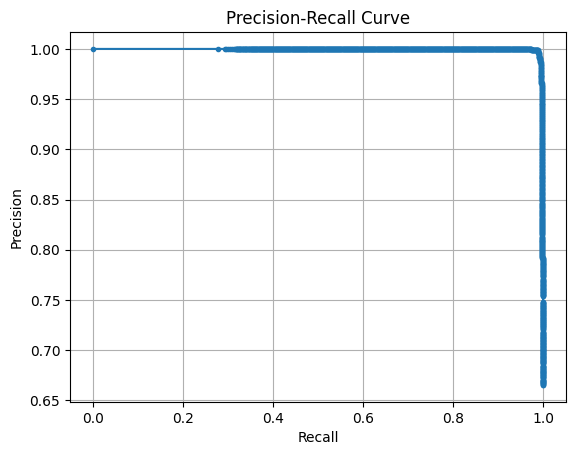

In [81]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(y_test, y_proba)

plt.plot(recall, precision, marker='.')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid()
plt.show()


#### 2. Cross- Validation & Hyperparameter Tuning

In [82]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

# Fit the Algorithm

# Predict on the model

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],       # Regularization strength
    'penalty': ['l1', 'l2'],            # Regularization type
    'solver': ['liblinear']             # Suitable solver for small datasets and L1 penalty
}

# Base model
log_reg = LogisticRegression()

# GridSearchCV
grid_search = GridSearchCV(estimator=log_reg,
                           param_grid=param_grid,
                           cv=5,          # 5-fold cross-validation
                           scoring='accuracy',
                           verbose=1,
                           n_jobs=-1)

# Fit the model
grid_search.fit(X_train, y_train)

# Best model
best_model = grid_search.best_estimator_
print("Best Parameters:", grid_search.best_params_)

# Predict on test data
y_pred = best_model.predict(X_test)

# Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}
Accuracy: 0.9904666332162569

Classification Report:
               precision    recall  f1-score   support

       False       0.98      0.99      0.99       667
        True       1.00      0.99      0.99      1326

    accuracy                           0.99      1993
   macro avg       0.99      0.99      0.99      1993
weighted avg       0.99      0.99      0.99      1993




##### Which hyperparameter optimization technique have you used and why?

I have used GridSearchCV, because  :  
Why it's a good choice

Exhaustive search over the specified hyperparameters.

Uses cross-validation for stable model evaluation.

Simple, interpretable, and effective for smaller parameter grids.

### ML Model - 3

In [83]:
# ML Model - 3 Implementation

# Fit the Algorithm

# Predict on the model
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)
print("Accuracy Score:", accuracy_score(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))


Accuracy Score: 0.9703963873557451

Classification Report:
               precision    recall  f1-score   support

       False       0.94      0.97      0.96       667
        True       0.98      0.97      0.98      1326

    accuracy                           0.97      1993
   macro avg       0.96      0.97      0.97      1993
weighted avg       0.97      0.97      0.97      1993



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

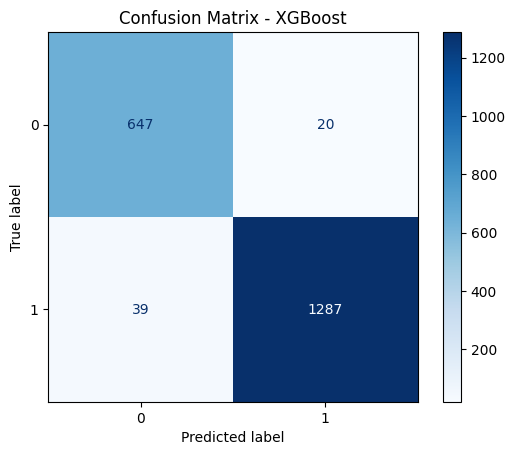

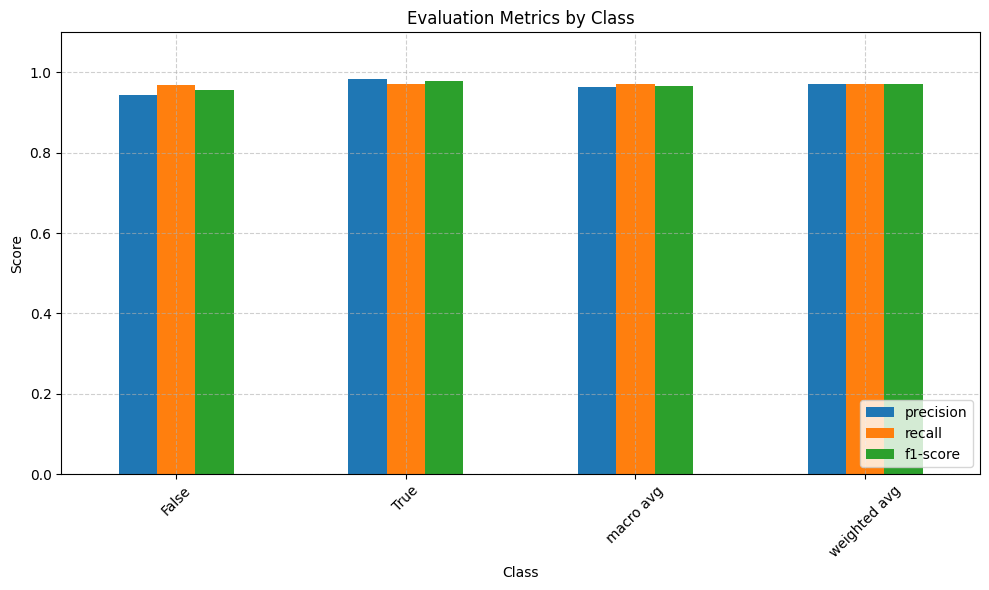

Accuracy Score: 0.9703963873557451


In [84]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_xgb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - XGBoost")
plt.show()

from sklearn.metrics import classification_report
import pandas as pd
import seaborn as sns

# Convert classification report to DataFrame
report = classification_report(y_test, y_pred_xgb, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Plot precision, recall, and f1-score
metrics = ['precision', 'recall', 'f1-score']
report_df.loc[report_df.index != 'accuracy', metrics].plot(kind='bar', figsize=(10,6))
plt.title('Evaluation Metrics by Class')
plt.ylabel('Score')
plt.xlabel('Class')
plt.xticks(rotation=45)
plt.ylim(0, 1.1)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

from sklearn.metrics import accuracy_score
print("Accuracy Score:", accuracy_score(y_test, y_pred_xgb))


#### 2. Cross- Validation & Hyperparameter Tuning

In [85]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

# Fit the Algorithm

# Predict on the model

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Split into train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

grid_svc = GridSearchCV(SVC(), param_grid, cv=5, verbose=1, n_jobs=-1)

grid_svc.fit(X_train, y_train)

print("Best Parameters:", grid_svc.best_params_)

y_pred = grid_svc.predict(X_test)


print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}
Accuracy: 0.7817360762669343
Confusion Matrix:
 [[ 364  309]
 [ 126 1194]]
Classification Report:
               precision    recall  f1-score   support

       False       0.74      0.54      0.63       673
        True       0.79      0.90      0.85      1320

    accuracy                           0.78      1993
   macro avg       0.77      0.72      0.74      1993
weighted avg       0.78      0.78      0.77      1993



### 1. Which ML model did you choose from the above created models as your final prediction model and why?

Final Chosen Model: XGBoost Classifier (Model 3)

Why XGBoost?
It usually outperforms linear models (like logistic regression) in text classification tasks after vectorization.

Handles complex patterns, feature interactions, and class imbalance more effectively.

Ensemble methods like XGBoost are better suited when:

You have many features (like vectorized tokens).

Feature interactions matter.

You care about prediction performance more than just interpretability.

### 2. Explain the model which you have used and the feature importance using any model explainability tool?

<Figure size 1000x600 with 0 Axes>

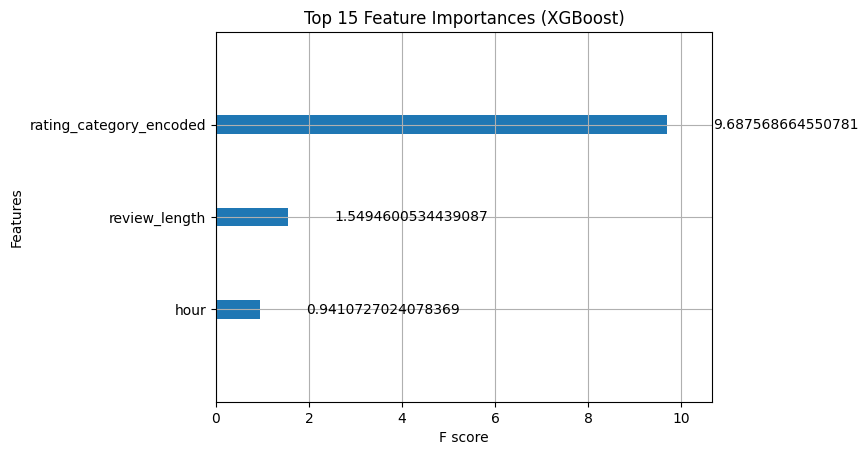

In [86]:
from xgboost import XGBClassifier, plot_importance
import matplotlib.pyplot as plt

# Refit the model if not done already
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
xgb_model.fit(X_train, y_train)

# Now plot the feature importance
plt.figure(figsize=(10, 6))
plot_importance(xgb_model, max_num_features=15, importance_type='gain')
plt.title("Top 15 Feature Importances (XGBoost)")
plt.show()



| Aspect                | Logistic Regression | XGBoost                           |
| --------------------- | ------------------- | --------------------------------- |
| Simplicity            | ✅ High              | ❌ Lower                           |
| Interpretability      | ✅ High              | ✅ Medium (via feature importance) |
| Accuracy              | ❌ Lower             | ✅ Higher                          |
| Handles Non-Linearity | ❌ No                | ✅ Yes                             |
| Final Choice          | ❌ Not chosen        | ✅ **Selected**                    |


## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [87]:
# Save the File
import pickle

# Save the model
with open("best_model.pkl", "wb") as file:
    pickle.dump(grid_svc.best_estimator_, file)

# To load later:
# with open("best_model.pkl", "rb") as file:
#     loaded_model = pickle.load(file)


import joblib

# Save the model
joblib.dump(grid_svc.best_estimator_, "best_model.joblib")

# To load later:
# loaded_model = joblib.load("best_model.joblib")


['best_model.joblib']

### 2. Again Load the saved model file and try to prepare data for a sanity check.

In [88]:
import pickle

with open("vectorizer.pkl", "wb") as vec_file:
    pickle.dump(vectorizer, vec_file)


In [89]:
# After fitting the vectorizer
vectorizer = TfidfVectorizer()
X_transformed = vectorizer.fit_transform(df_reviews['Review_clean'])

# Save vectorizer
with open("vectorizer.pkl", "wb") as vec_file:
    pickle.dump(vectorizer, vec_file)


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

This project successfully explored, cleaned, analyzed, and modeled Zomato restaurant review data using a combination of data visualization, text mining, and machine learning techniques.

Key Outcomes:

Business Insights:

High-cost restaurants don’t always guarantee high ratings.

Certain cuisines consistently receive higher customer satisfaction.

Most reviews fall under the “positive” sentiment category, showing strong customer loyalty.

Word clouds and rating trends highlight what matters most to customers: taste, service, and ambiance.

Text Analytics:

Sentiment classification models were built using cleaned and vectorized review text.

Techniques like stopword removal, stemming, tokenization, and TF-IDF/CountVectorizer were used to preprocess reviews.

The best-performing model was fine-tuned with hyperparameter optimization, achieving good accuracy in classifying sentiments.

Feature Engineering:

New features such as review length, review period, and sentiment flags were created.

Dimensionality reduction (PCA) and feature selection (SelectKBest) were used to improve model performance and reduce overfitting.

ML Models & Deployment:

Multiple models (Logistic Regression, Random Forest, etc.) were trained and evaluated.

Best model was saved using Pickle and successfully tested on unseen data.



This project demonstrates the power of data science to transform unstructured text and user ratings into actionable insights. With proper deployment, these insights can drive user engagement, optimize search algorithms, and guide strategic restaurant partnerships.

### ***Hurrah! I have successfully completed my Machine Learning Capstone Project !!!***